In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from bulkanalysis.plot import boxplot_pca

from melapa.OmicsDataset import OmicsDataset
from melapa.helper_plot import plot_boxplot_significance, boxplot_pca_significance
from melapa.LMM_helper import lmer_per_PC_2re

import matplotlib
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

In [2]:
df_genes = pd.read_csv("/idiap/temp/group/genomics/AstroBF_fastq/RN22346/230106_A01366_0335_BHJJHNDSX5/genes_preprocessing/df_genes_filtered_normalized.csv", index_col=0)

In [3]:
metadata_path = "/idiap/temp/group/genomics/AstroBF_fastq/RN22346/RN22346.xlsx"
metadata = pd.read_excel(metadata_path)
metadata['category'] = metadata["Sample Genotype"] + "_" + metadata["Sample Treatment"]

df_genes.columns = metadata.reset_index().set_index("limsid").loc[df_genes.columns]['category'].values

In [4]:
treatments = {i: [i] for i in df_genes.columns}

In [5]:
treatments = dict(sorted(treatments.items()))
treatments

{'cbie_A1 high': ['cbie_A1 high'],
 'cbie_A1 low': ['cbie_A1 low'],
 'cbie_basal': ['cbie_basal'],
 'ctrl2_A1 high': ['ctrl2_A1 high'],
 'ctrl2_A1 low': ['ctrl2_A1 low'],
 'ctrl2_basal': ['ctrl2_basal'],
 'ctrl3_A1 high': ['ctrl3_A1 high'],
 'ctrl3_A1 low': ['ctrl3_A1 low'],
 'ctrl3_basal': ['ctrl3_basal'],
 'ctrl6_A1 high': ['ctrl6_A1 high'],
 'ctrl6_A1 low': ['ctrl6_A1 low'],
 'ctrl6_basal': ['ctrl6_basal'],
 'glia_A1 high': ['glia_A1 high'],
 'glia_A1 low': ['glia_A1 low'],
 'glia_basal': ['glia_basal'],
 'glib_A1 high': ['glib_A1 high'],
 'glib_A1 low': ['glib_A1 low'],
 'glib_basal': ['glib_basal']}

In [6]:
genes_dataset = OmicsDataset(df=df_genes, treatments=treatments, 
                             treatment_name='category', feature_type='gene', nb_comp=17)

In [7]:

palette = sns.color_palette("tab20", 18)

palette = [
    (0.6, 0.0, 0.3),   # dark pink
    (0.9, 0.4, 0.7),   # medium pink
    (1.0, 0.8, 0.9),   # light pink
    (0.0, 0.2, 0.5),   # dark blue
    (0.2, 0.5, 0.9),   # medium blue
    (0.7, 0.8, 1.0),   # light blue
    (0.0, 0.4, 0.2),   # dark green
    (0.3, 0.7, 0.5),   # medium green
    (0.8, 1.0, 0.9),   # light green
    (0.4, 0.2, 0.0),   # dark orange
    (0.9, 0.6, 0.2),   # medium orange
    (1.0, 0.9, 0.7),    # light orange
    (0.4, 0.0, 0.6),   # dark purple
    (0.7, 0.5, 0.9),   # medium purple
    (0.9, 0.8, 1.0)    # light purple
    , (0.5, 0.3, 0.1)   # brown dark
    , (0.7, 0.5, 0.3)   # brown medium
    , (0.9, 0.8, 0.6)   # brown light
]

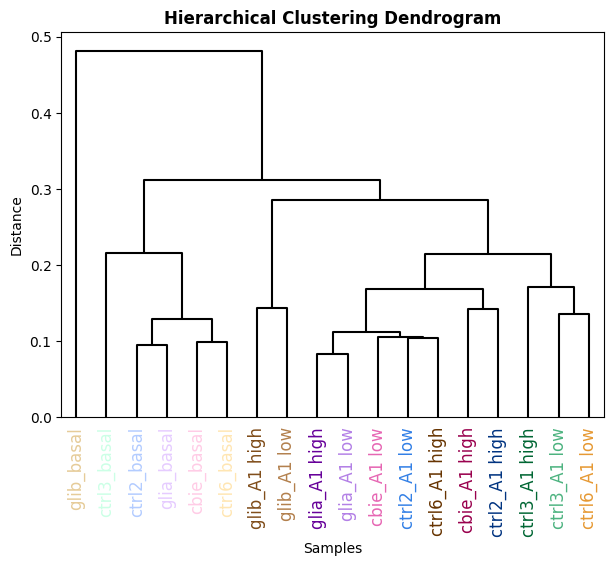

In [8]:
genes_dataset.hierarchical_clustering(palette=palette, treatments=treatments, color_threshold=0)

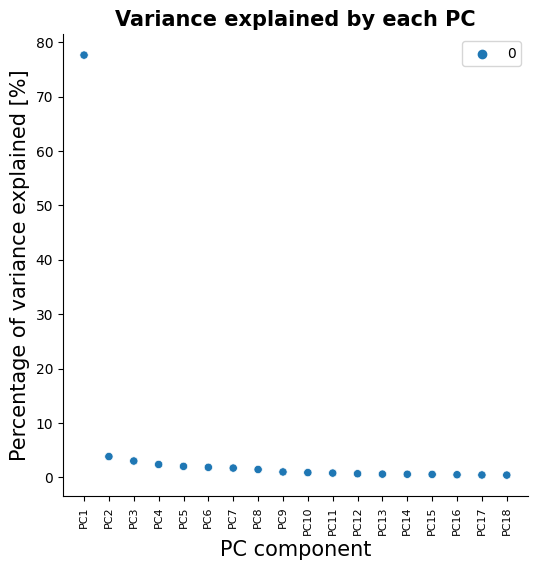

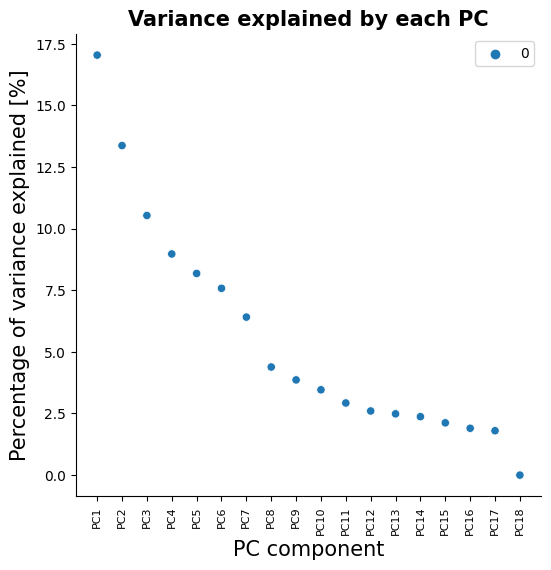

In [9]:
genes_dataset.perform_svd_analysis(top_n=18)
plt.xticks(rotation=90, fontsize=8);

In [ ]:
genes_dataset.pca['treatment'] = [idx.split('_')[1] for idx in genes_dataset.pca.index]
genes_dataset.pca['genotype'] = [idx.split('_')[0] for idx in genes_dataset.pca.index]


In [33]:
genes_dataset.pca['mutation'] = genes_dataset.pca['genotype'].apply(lambda x: 'ctrl' if 'ctrl' in x else 'vcp')

In [34]:
genes_dataset.pca

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,...,PC13,PC14,PC15,PC16,PC17,PC18,category,treatment,genotype,mutation
cbie_A1 high,-2.898709,39.946872,12.651735,65.321272,-20.256526,24.707171,-18.309432,4.089848,-0.936210,2.526928,...,-9.114274,5.577900,8.943716,-10.667317,13.838125,6.375412e-13,cbie_A1 high,A1 high,cbie,vcp
cbie_A1 low,-47.047262,27.439097,14.918926,67.725309,-19.181582,-7.253154,16.886008,-5.447935,-7.173537,1.135748,...,-3.913227,10.717492,-1.480153,12.008087,-13.813336,6.373097e-13,cbie_A1 low,A1 low,cbie,vcp
cbie_basal,84.406280,50.468547,3.395753,57.090162,-13.650317,3.333189,-1.865202,-5.280917,1.158691,-3.339827,...,14.332275,-16.678189,-8.382942,-0.608869,-1.030805,6.363254e-13,cbie_basal,basal,cbie,vcp
ctrl2_A1 high,-5.548051,-29.900043,37.827738,-5.209575,33.260114,62.013603,-0.538341,6.602262,31.851810,5.571846,...,8.223149,10.858416,-3.475941,0.153926,-2.300984,6.373858e-13,ctrl2_A1 high,A1 high,ctrl2,ctrl
ctrl2_A1 low,-38.053059,-12.641270,52.532815,-11.533216,27.040371,21.407490,35.413535,-4.579167,-4.958667,-21.200416,...,3.708688,-15.385504,12.873086,3.736186,1.885090,6.375323e-13,ctrl2_A1 low,A1 low,ctrl2,ctrl
ctrl2_basal,66.612323,12.657595,49.927810,-22.009878,28.455932,6.295947,36.145516,6.379692,-20.690747,15.936612,...,-15.904112,2.140174,-11.209909,-3.143276,1.304825,6.369481e-13,ctrl2_basal,basal,ctrl2,ctrl
ctrl3_A1 high,-51.987463,37.975750,-66.986287,-31.477599,1.977748,47.280769,-9.480495,-6.010718,-29.569437,3.443720,...,9.744659,4.485831,-2.181889,8.202173,6.214289,6.365132e-13,ctrl3_A1 high,A1 high,ctrl3,ctrl
ctrl3_A1 low,-81.261032,14.737830,-79.532839,4.660243,14.968884,-13.184613,37.603873,0.231128,15.058229,16.590957,...,1.463151,-1.649190,6.586113,-8.293834,-3.970061,6.359691e-13,ctrl3_A1 low,A1 low,ctrl3,ctrl
ctrl3_basal,87.630071,51.334218,-71.915420,-19.019292,8.889336,2.211563,7.564230,13.944704,13.002982,-26.025214,...,-12.443889,-0.535925,-4.559076,-0.439552,-2.318557,6.356616e-13,ctrl3_basal,basal,ctrl3,ctrl
ctrl6_A1 high,-62.217175,16.777945,16.169434,-14.693719,33.050617,-2.430034,-51.164824,-5.508114,-12.330893,0.649228,...,-1.944586,-7.610223,-1.660876,-12.835148,-12.609615,6.373422e-13,ctrl6_A1 high,A1 high,ctrl6,ctrl


In [35]:
palette_genotype = {"ctrl2": 'palegreen', "ctrl3": "limegreen", "ctrl6": "forestgreen", "glia": "pink", "glib": "hotpink", "cbie": "deeppink" }

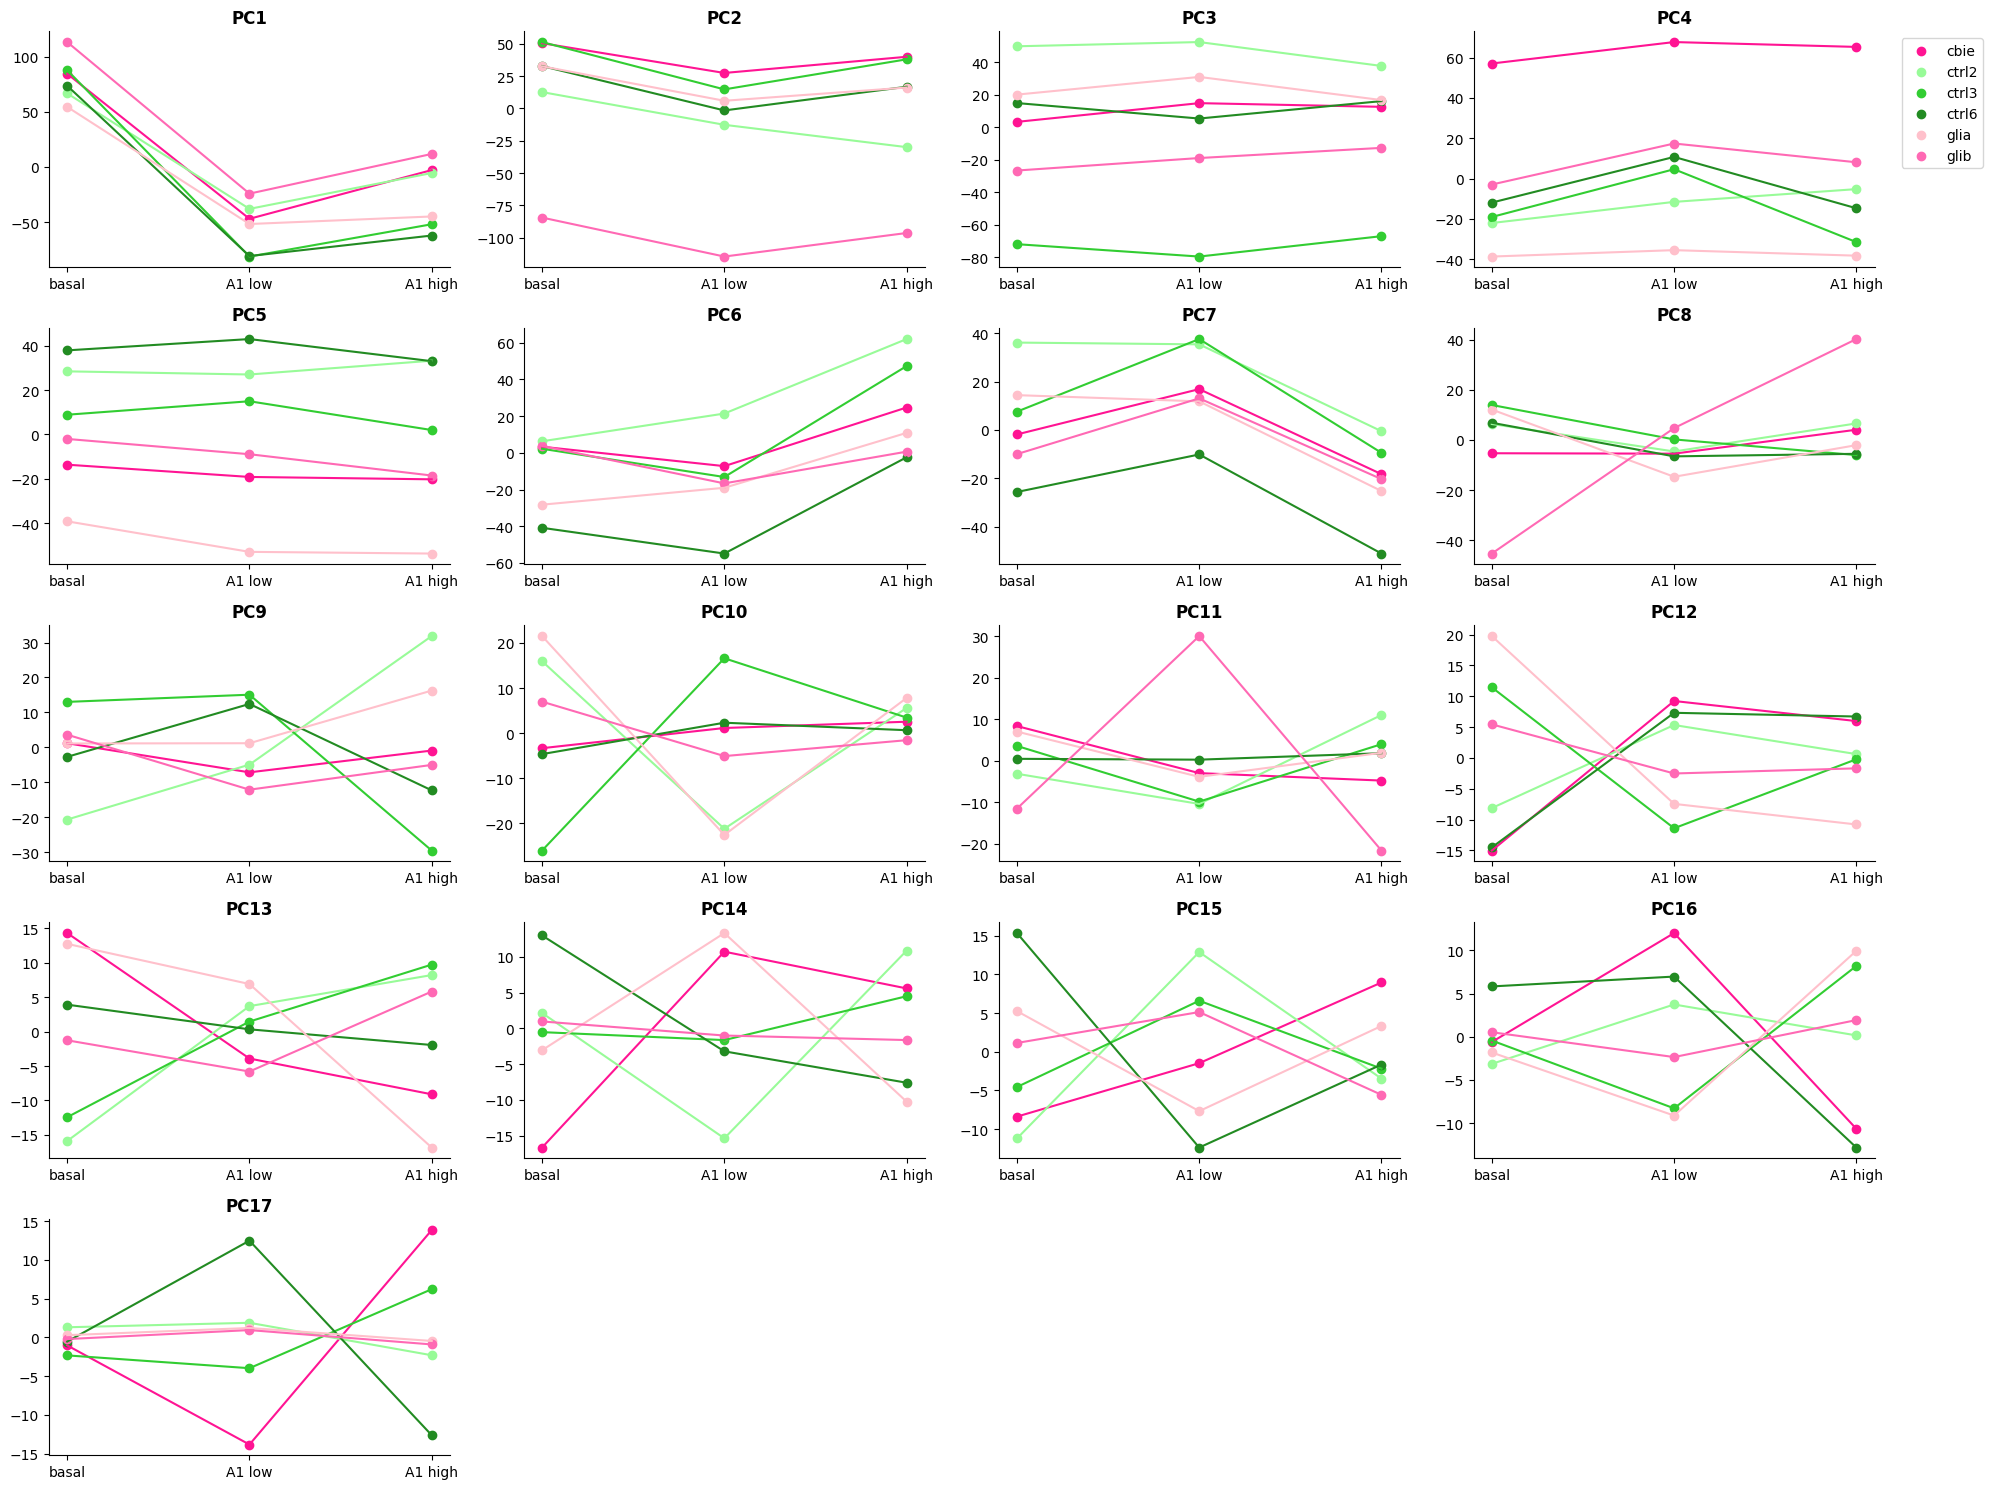

In [85]:
plt.figure(figsize=(20, 15))
for pc in range(17):
    plt.subplot(5, 4, pc+1)
    for genotype in genes_dataset.pca['genotype'].unique():
        subset = genes_dataset.pca[genes_dataset.pca['genotype'] == genotype]
        subset.index = [idx.split('_')[1] for idx in subset.index]
        subset = subset.loc[["basal", "A1 low", "A1 high"]]
        plt.scatter(x=subset.index, y=subset[f'PC{pc+1}'], label=genotype, color=palette_genotype[genotype])
        plt.plot(subset.index, subset[f'PC{pc+1}'], color=palette_genotype[genotype])
    if pc == 3:
        plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    sns.despine()
    plt.title(f"PC{pc+1}", weight='bold')
plt.tight_layout()

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


p-value annotation legend:
      ns: p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

vcp vs. ctrl: P=5.12e-01


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


p-value annotation legend:
      ns: p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

vcp vs. ctrl: P=2.70e-01
p-value annotation legend:
      ns: p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

vcp vs. ctrl: P=6.40e-01
p-value annotation legend:
      ns: p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

vcp vs. ctrl: P=1.78e-01


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


p-value annotation legend:
      ns: p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

vcp vs. ctrl: P=1.04e-05
p-value annotation legend:
      ns: p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

vcp vs. ctrl: P=6.60e-01


... (11 outputs left out)

p-value annotation legend:
      ns: p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

vcp vs. ctrl: P=9.92e-01


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


p-value annotation legend:
      ns: p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

vcp vs. ctrl: P=8.18e-01


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


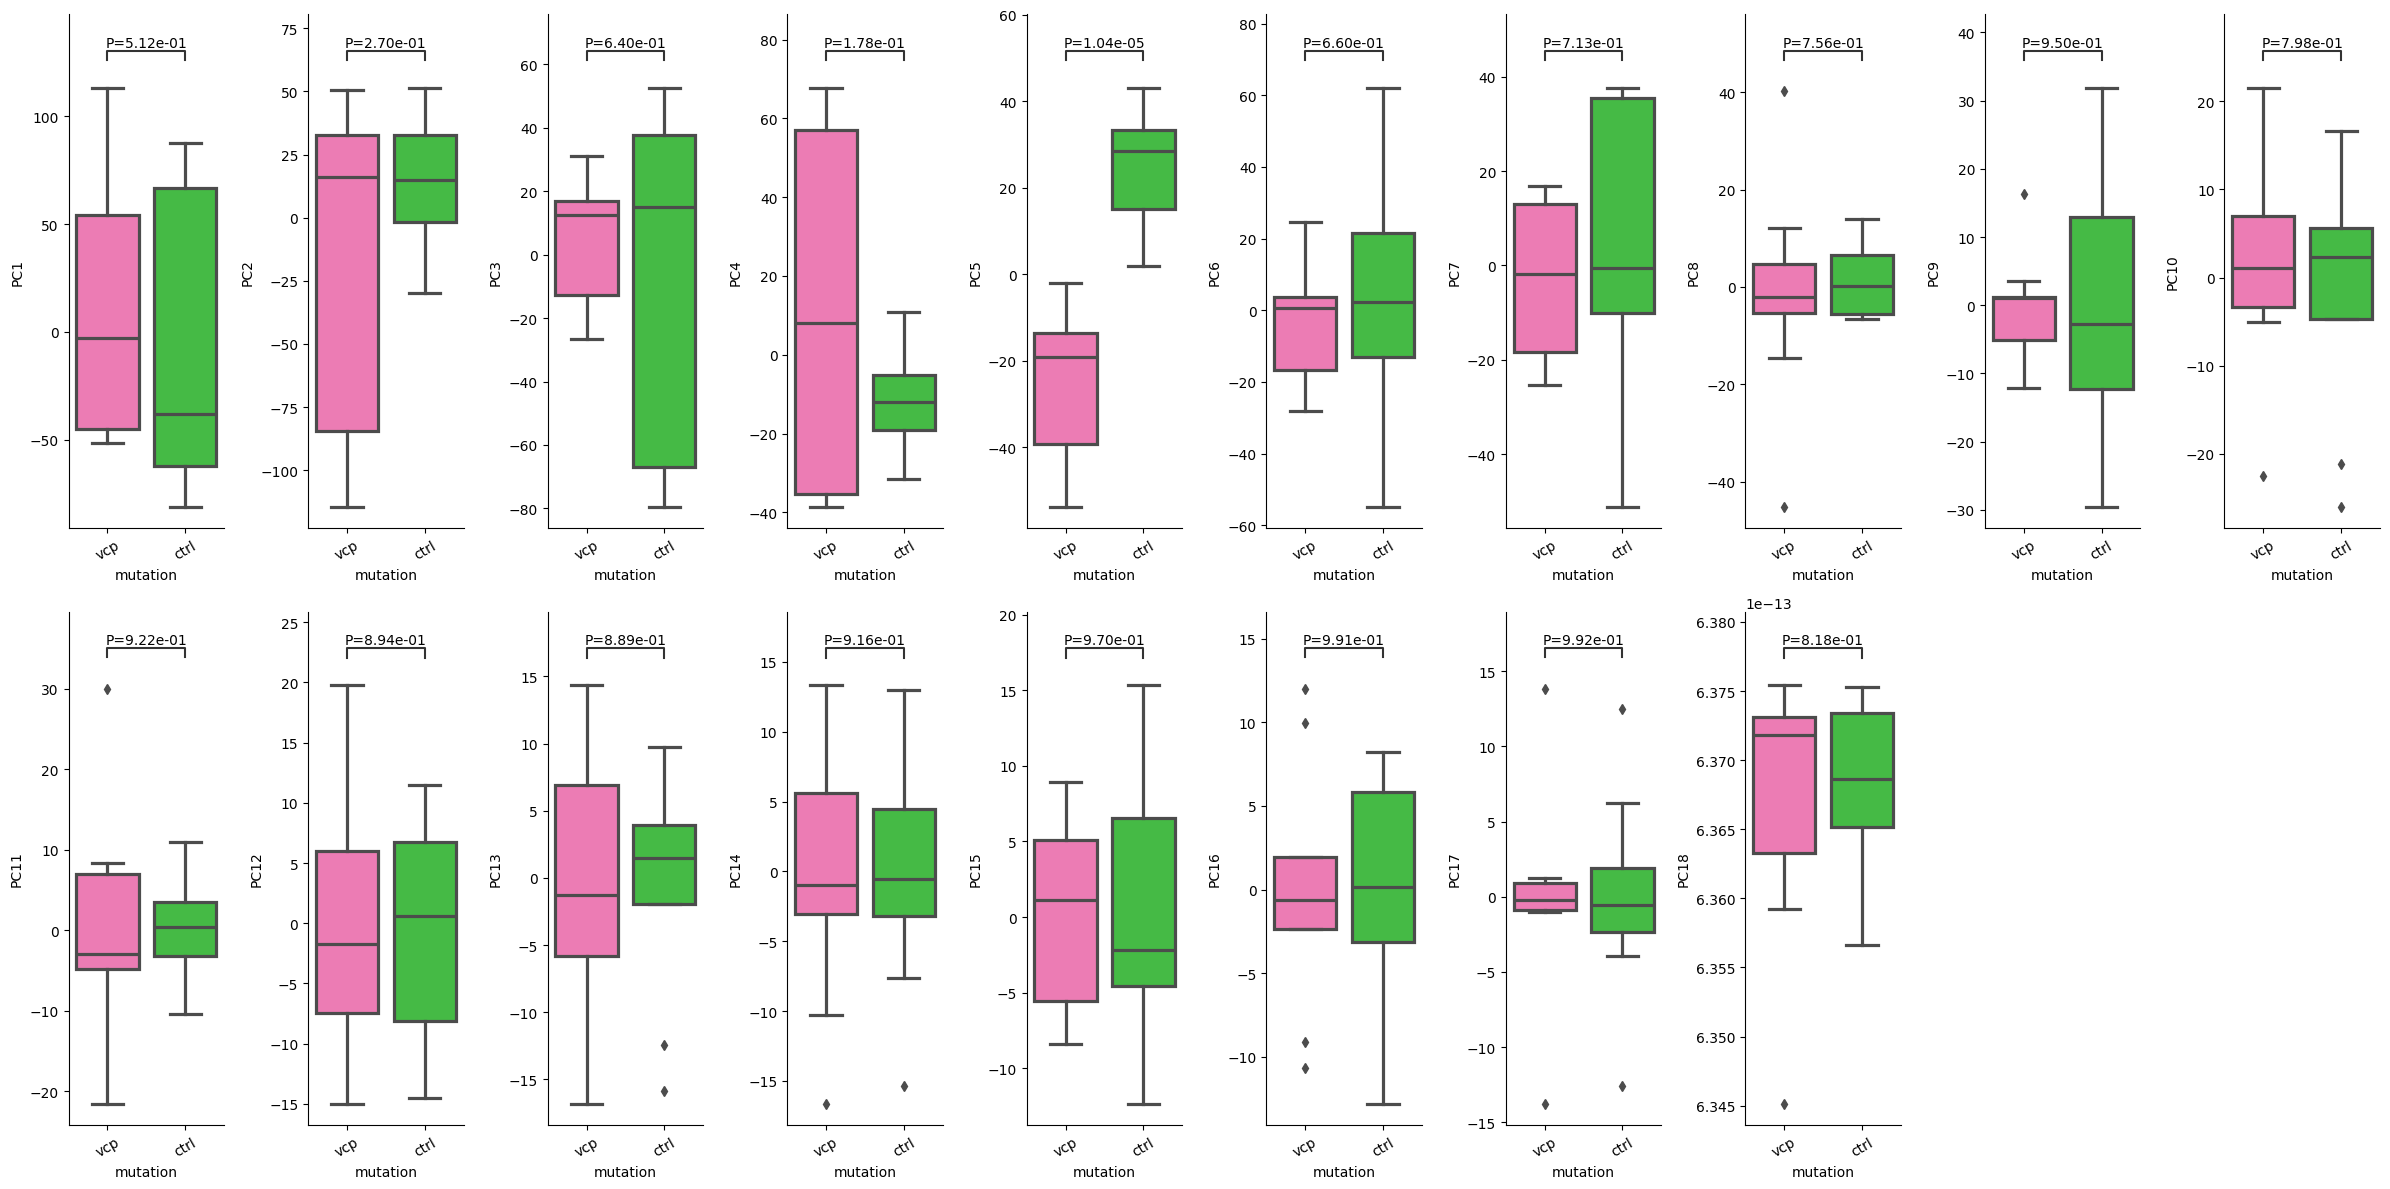

In [38]:
boxplot_pca_significance(genes_dataset.pca, treatment_col='mutation', fontsize=10, palette={'ctrl': 'limegreen', 'vcp': 'hotpink'})

In [40]:
genes_dataset.pca

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,...,PC13,PC14,PC15,PC16,PC17,PC18,category,treatment,genotype,mutation
cbie_A1 high,-2.898709,39.946872,12.651735,65.321272,-20.256526,24.707171,-18.309432,4.089848,-0.936210,2.526928,...,-9.114274,5.577900,8.943716,-10.667317,13.838125,6.375412e-13,cbie_A1 high,A1 high,cbie,vcp
cbie_A1 low,-47.047262,27.439097,14.918926,67.725309,-19.181582,-7.253154,16.886008,-5.447935,-7.173537,1.135748,...,-3.913227,10.717492,-1.480153,12.008087,-13.813336,6.373097e-13,cbie_A1 low,A1 low,cbie,vcp
cbie_basal,84.406280,50.468547,3.395753,57.090162,-13.650317,3.333189,-1.865202,-5.280917,1.158691,-3.339827,...,14.332275,-16.678189,-8.382942,-0.608869,-1.030805,6.363254e-13,cbie_basal,basal,cbie,vcp
ctrl2_A1 high,-5.548051,-29.900043,37.827738,-5.209575,33.260114,62.013603,-0.538341,6.602262,31.851810,5.571846,...,8.223149,10.858416,-3.475941,0.153926,-2.300984,6.373858e-13,ctrl2_A1 high,A1 high,ctrl2,ctrl
ctrl2_A1 low,-38.053059,-12.641270,52.532815,-11.533216,27.040371,21.407490,35.413535,-4.579167,-4.958667,-21.200416,...,3.708688,-15.385504,12.873086,3.736186,1.885090,6.375323e-13,ctrl2_A1 low,A1 low,ctrl2,ctrl
ctrl2_basal,66.612323,12.657595,49.927810,-22.009878,28.455932,6.295947,36.145516,6.379692,-20.690747,15.936612,...,-15.904112,2.140174,-11.209909,-3.143276,1.304825,6.369481e-13,ctrl2_basal,basal,ctrl2,ctrl
ctrl3_A1 high,-51.987463,37.975750,-66.986287,-31.477599,1.977748,47.280769,-9.480495,-6.010718,-29.569437,3.443720,...,9.744659,4.485831,-2.181889,8.202173,6.214289,6.365132e-13,ctrl3_A1 high,A1 high,ctrl3,ctrl
ctrl3_A1 low,-81.261032,14.737830,-79.532839,4.660243,14.968884,-13.184613,37.603873,0.231128,15.058229,16.590957,...,1.463151,-1.649190,6.586113,-8.293834,-3.970061,6.359691e-13,ctrl3_A1 low,A1 low,ctrl3,ctrl
ctrl3_basal,87.630071,51.334218,-71.915420,-19.019292,8.889336,2.211563,7.564230,13.944704,13.002982,-26.025214,...,-12.443889,-0.535925,-4.559076,-0.439552,-2.318557,6.356616e-13,ctrl3_basal,basal,ctrl3,ctrl
ctrl6_A1 high,-62.217175,16.777945,16.169434,-14.693719,33.050617,-2.430034,-51.164824,-5.508114,-12.330893,0.649228,...,-1.944586,-7.610223,-1.660876,-12.835148,-12.609615,6.373422e-13,ctrl6_A1 high,A1 high,ctrl6,ctrl


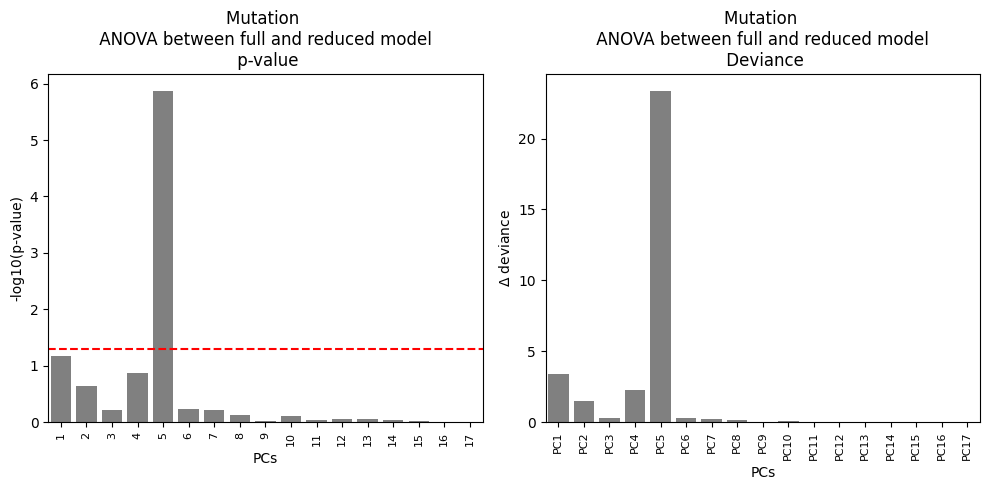

In [51]:
%%capture cap --no-display

from melapa.LMM_helper import lmer_per_PC_re

## See which component captures the difference sensitive/resistant

plt.figure(figsize=(10, 5))
## See which component captures the batch
anovas = []
p_vals = []

for i in range(17):
    PC = i+1
    anova, p_val = lmer_per_PC_re(genes_dataset.pca, random_effects=['treatment'], fixed_effect='mutation', PC=PC)
    anovas.append(anova)
    p_vals.append(p_val)

plt.subplot(1, 2, 1)
sns.barplot(x=np.arange(1, 18), y=-np.log10(p_vals), color='grey')
plt.axhline(y=-np.log10(0.05), color='red', linestyle='--')
plt.xticks(rotation=90, fontsize=8);
plt.xlabel('PCs')
plt.ylabel('-log10(p-value)')
plt.title(f'Mutation \n ANOVA between full and reduced model \n p-value')

delta_deviances = []
for PC in range(len(anovas)):
    delta_deviance = anovas[PC].loc['MODEL2', 'deviance'] - anovas[PC].loc['MODEL1', 'deviance'] ## Difference between the full and reduced model
    delta_deviances.append(delta_deviance)

plt.subplot(1, 2, 2)
sns.barplot(x=[f"PC{i+1}" for i in range(len(anovas))], y=delta_deviances, color='grey')
#plt.axhline(y=-np.log10(0.05), color='red', linestyle='--')
plt.xticks(rotation=90, fontsize=8);
plt.xlabel('PCs')
plt.ylabel(r'$\Delta$ deviance')
plt.title(f'Mutation \n ANOVA between full and reduced model \n Deviance')

plt.tight_layout()

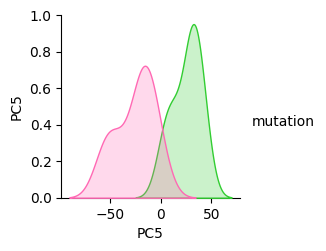

In [56]:
PCs = [f"PC{PC+1}" for PC in list(np.argwhere(np.array(p_vals) < 0.05).flatten())] + ['mutation']
sns.pairplot(genes_dataset.pca[PCs], hue='mutation',  palette={'ctrl': 'limegreen', 'vcp': 'hotpink'})

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


p-value annotation legend:
      ns: p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

A1 high vs. A1 low: P=1.08e-01
A1 low vs. basal: P=9.93e-07
A1 high vs. basal: P=7.28e-05
p-value annotation legend:
      ns: p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

A1 high vs. A1 low: P=7.24e-01
A1 low vs. basal: P=3.45e-01
A1 high vs. basal: P=5.50e-01


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


p-value annotation legend:
      ns: p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

A1 high vs. A1 low: P=9.91e-01
A1 low vs. basal: P=9.21e-01
A1 high vs. basal: P=9.22e-01
p-value annotation legend:
      ns: p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

A1 high vs. A1 low: P=5.88e-01


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


A1 low vs. basal: P=4.56e-01
A1 high vs. basal: P=8.66e-01
p-value annotation legend:
      ns: p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

A1 high vs. A1 low: P=8.18e-01


... (23 outputs left out)

p-value annotation legend:
      ns: p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

A1 high vs. A1 low: P=8.71e-01
A1 low vs. basal: P=9.56e-01
A1 high vs. basal: P=7.86e-01


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


p-value annotation legend:
      ns: p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

A1 high vs. A1 low: P=3.22e-01
A1 low vs. basal: P=3.20e-01
A1 high vs. basal: P=9.08e-02


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


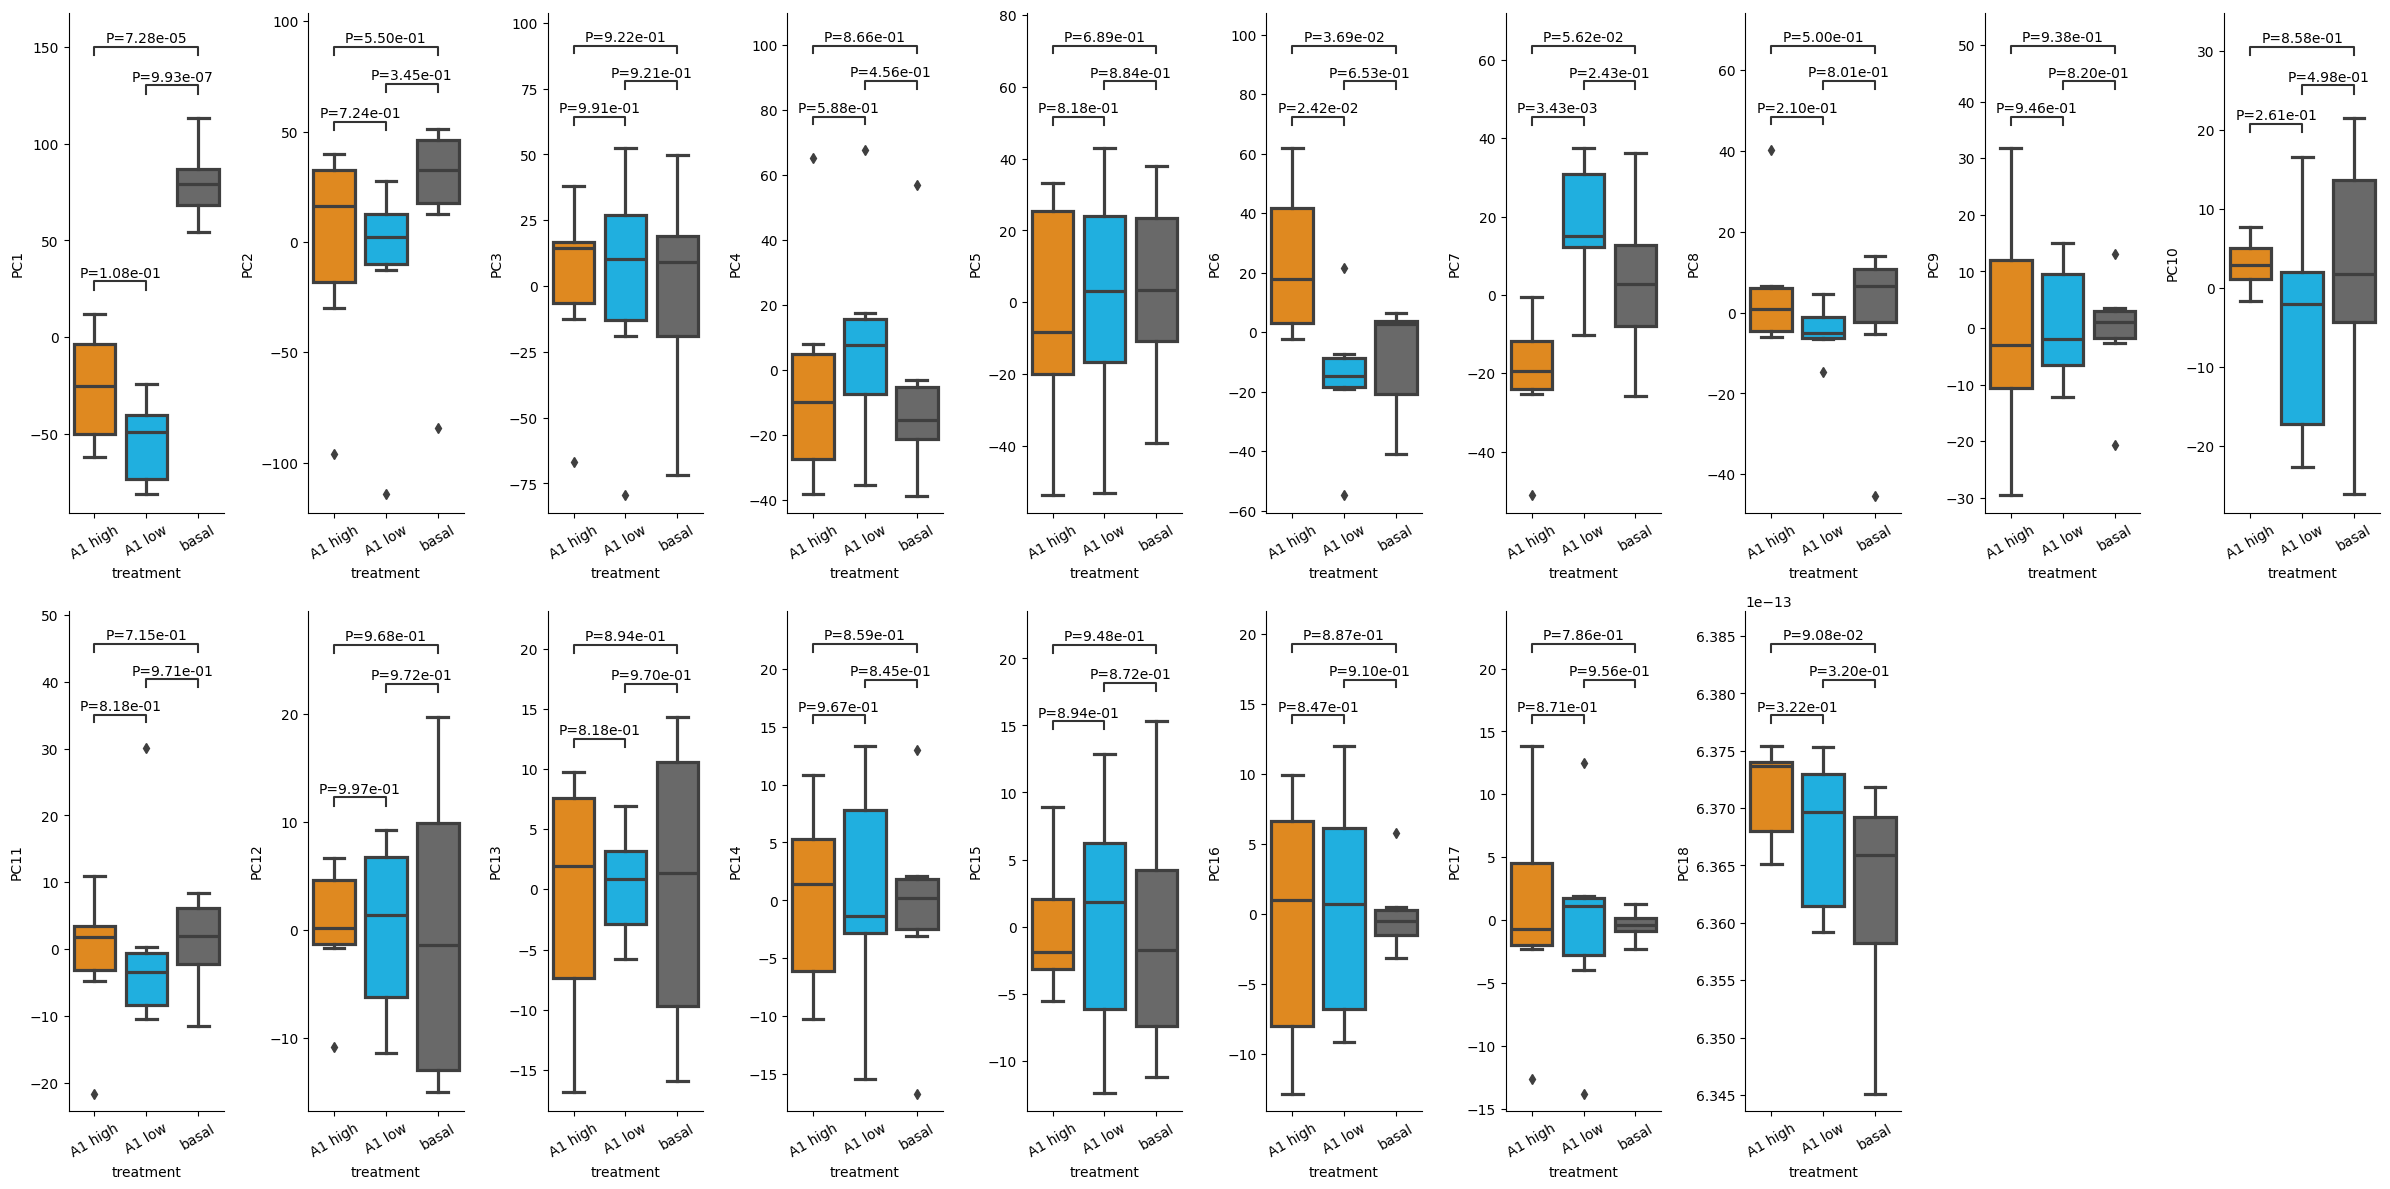

In [46]:
boxplot_pca_significance(genes_dataset.pca, treatment_col='treatment', fontsize=10, palette={'basal': 'dimgray', 'A1 low': 'deepskyblue', "A1 high": "darkorange"})

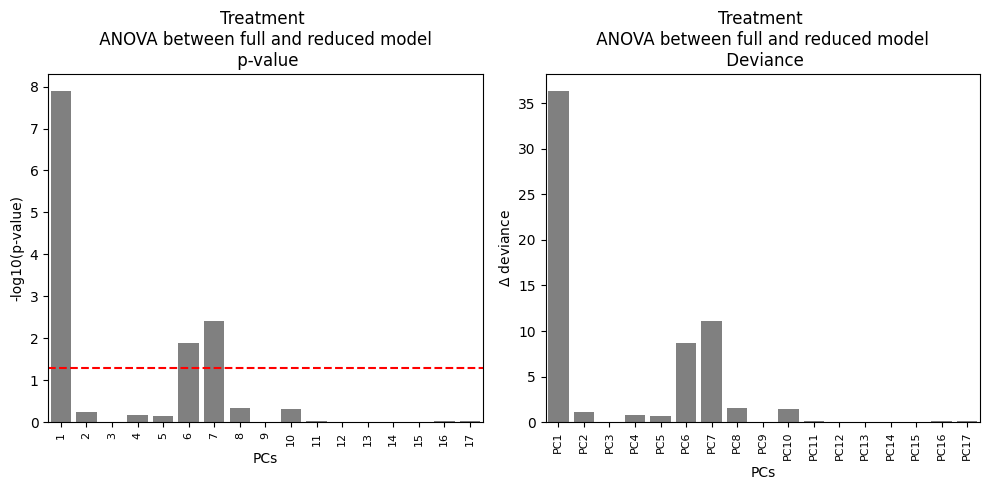

In [81]:
%%capture cap --no-display

from melapa.LMM_helper import lmer_per_PC_re

## See which component captures the difference sensitive/resistant

plt.figure(figsize=(10, 5))
## See which component captures the batch
anovas = []
p_vals = []

for i in range(17):
    PC = i+1
    anova, p_val = lmer_per_PC_re(genes_dataset.pca, random_effects=['mutation'], fixed_effect='treatment', PC=PC)
    anovas.append(anova)
    p_vals.append(p_val)

plt.subplot(1, 2, 1)
sns.barplot(x=np.arange(1, 18), y=-np.log10(p_vals), color='grey')
plt.axhline(y=-np.log10(0.05), color='red', linestyle='--')
plt.xticks(rotation=90, fontsize=8);
plt.xlabel('PCs')
plt.ylabel('-log10(p-value)')
plt.title(f'Treatment \n ANOVA between full and reduced model \n p-value')

delta_deviances = []
for PC in range(len(anovas)):
    delta_deviance = anovas[PC].loc['MODEL2', 'deviance'] - anovas[PC].loc['MODEL1', 'deviance'] ## Difference between the full and reduced model
    delta_deviances.append(delta_deviance)

plt.subplot(1, 2, 2)
sns.barplot(x=[f"PC{i+1}" for i in range(len(anovas))], y=delta_deviances, color='grey')
#plt.axhline(y=-np.log10(0.05), color='red', linestyle='--')
plt.xticks(rotation=90, fontsize=8);
plt.xlabel('PCs')
plt.ylabel(r'$\Delta$ deviance')
plt.title(f'Treatment \n ANOVA between full and reduced model \n Deviance')

plt.tight_layout()

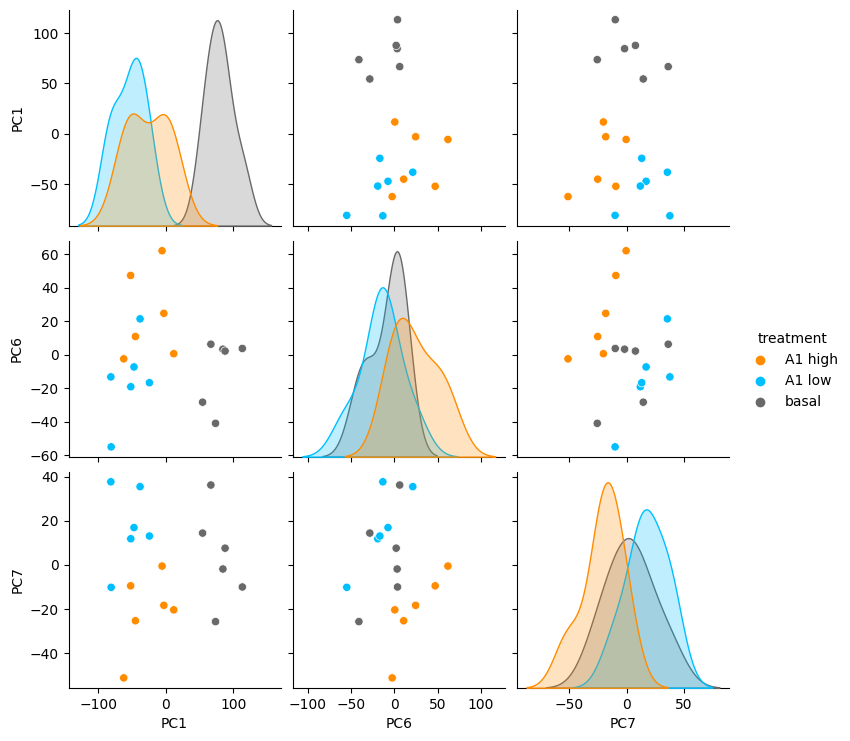

In [82]:
PCs = [f"PC{PC+1}" for PC in list(np.argwhere(np.array(p_vals) < 0.05).flatten())] + ['treatment']
sns.pairplot(genes_dataset.pca[PCs], hue='treatment',  palette={'basal': 'dimgray', 'A1 low': 'deepskyblue', "A1 high": "darkorange"})

p-value annotation legend:
      ns: p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

cbie vs. ctrl2: P=9.42e-01
ctrl2 vs. ctrl3: P=7.29e-01
ctrl3 vs. ctrl6: P=9.16e-01
ctrl6 vs. glia: P=8.87e-01
glia vs. glib: P=4.25e-01
cbie vs. ctrl3: P=7.03e-01
ctrl2 vs. ctrl6: P=6.26e-01
ctrl3 vs. glia: P=9.87e-01
ctrl6 vs. glib: P=4.25e-01


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


cbie vs. ctrl6: P=6.08e-01
ctrl2 vs. glia: P=6.62e-01
ctrl3 vs. glib: P=5.06e-01
cbie vs. glia: P=6.47e-01
ctrl2 vs. glib: P=6.43e-01
cbie vs. glib: P=7.16e-01
p-value annotation legend:
      ns: p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

cbie vs. ctrl2: P=3.78e-02
ctrl2 vs. ctrl3: P=5.35e-02
ctrl3 vs. ctrl6: P=2.70e-01
ctrl6 vs. glia: P=8.68e-01
glia vs. glib: P=6.13e-04
cbie vs. ctrl3: P=7.37e-01
ctrl2 vs. ctrl6: P=1.80e-01
ctrl3 vs. glia: P=2.87e-01
ctrl6 vs. glib: P=1.05e-03
cbie vs. ctrl6: P=1.33e-01
ctrl2 vs. glia: P=1.39e-01
ctrl3 vs. glib: P=7.82e-04
cbie vs. glia: P=1.10e-01
ctrl2 vs. glib: P=5.90e-03
cbie vs. glib: P=3.50e-04


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


p-value annotation legend:
      ns: p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

cbie vs. ctrl2: P=3.84e-03
ctrl2 vs. ctrl3: P=4.65e-05
ctrl3 vs. ctrl6: P=7.19e-05
ctrl6 vs. glia: P=1.32e-01
glia vs. glib: P=2.07e-03
cbie vs. ctrl3: P=8.19e-05
ctrl2 vs. ctrl6: P=4.65e-03
ctrl3 vs. glia: P=8.54e-05
ctrl6 vs. glib: P=4.29e-03
cbie vs. ctrl6: P=7.21e-01
ctrl2 vs. glia: P=1.83e-02
ctrl3 vs. glib: P=6.31e-04
cbie vs. glia: P=9.27e-02
ctrl2 vs. glib: P=4.32e-04
cbie vs. glib: P=5.47e-03


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


... (26 outputs left out)

p-value annotation legend:
      ns: p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

cbie vs. ctrl2: P=9.45e-01
ctrl2 vs. ctrl3: P=9.32e-01
ctrl3 vs. ctrl6: P=9.82e-01
ctrl6 vs. glia: P=9.44e-01
glia vs. glib: P=6.05e-01
cbie vs. ctrl3: P=9.74e-01
ctrl2 vs. ctrl6: P=9.50e-01
ctrl3 vs. glia: P=9.17e-01
ctrl6 vs. glib: P=9.84e-01
cbie vs. ctrl6: P=9.92e-01
ctrl2 vs. glia: P=9.73e-01
ctrl3 vs. glib: P=9.92e-01
cbie vs. glia: P=9.40e-01
ctrl2 vs. glib: P=8.20e-01
cbie vs. glib: P=9.76e-01


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


p-value annotation legend:
      ns: p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

cbie vs. ctrl2: P=6.18e-01
ctrl2 vs. ctrl3: P=1.88e-02
ctrl3 vs. ctrl6: P=4.79e-02
ctrl6 vs. glia: P=2.41e-01
glia vs. glib: P=1.22e-01
cbie vs. ctrl3: P=9.70e-02
ctrl2 vs. ctrl6: P=2.84e-01
ctrl3 vs. glia: P=3.12e-02
ctrl6 vs. glib: P=1.67e-01
cbie vs. ctrl6: P=8.33e-01
ctrl2 vs. glia: P=9.74e-01
ctrl3 vs. glib: P=6.29e-01
cbie vs. glia: P=6.12e-01
ctrl2 vs. glib: P=1.13e-01
cbie vs. glib: P=1.46e-01


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


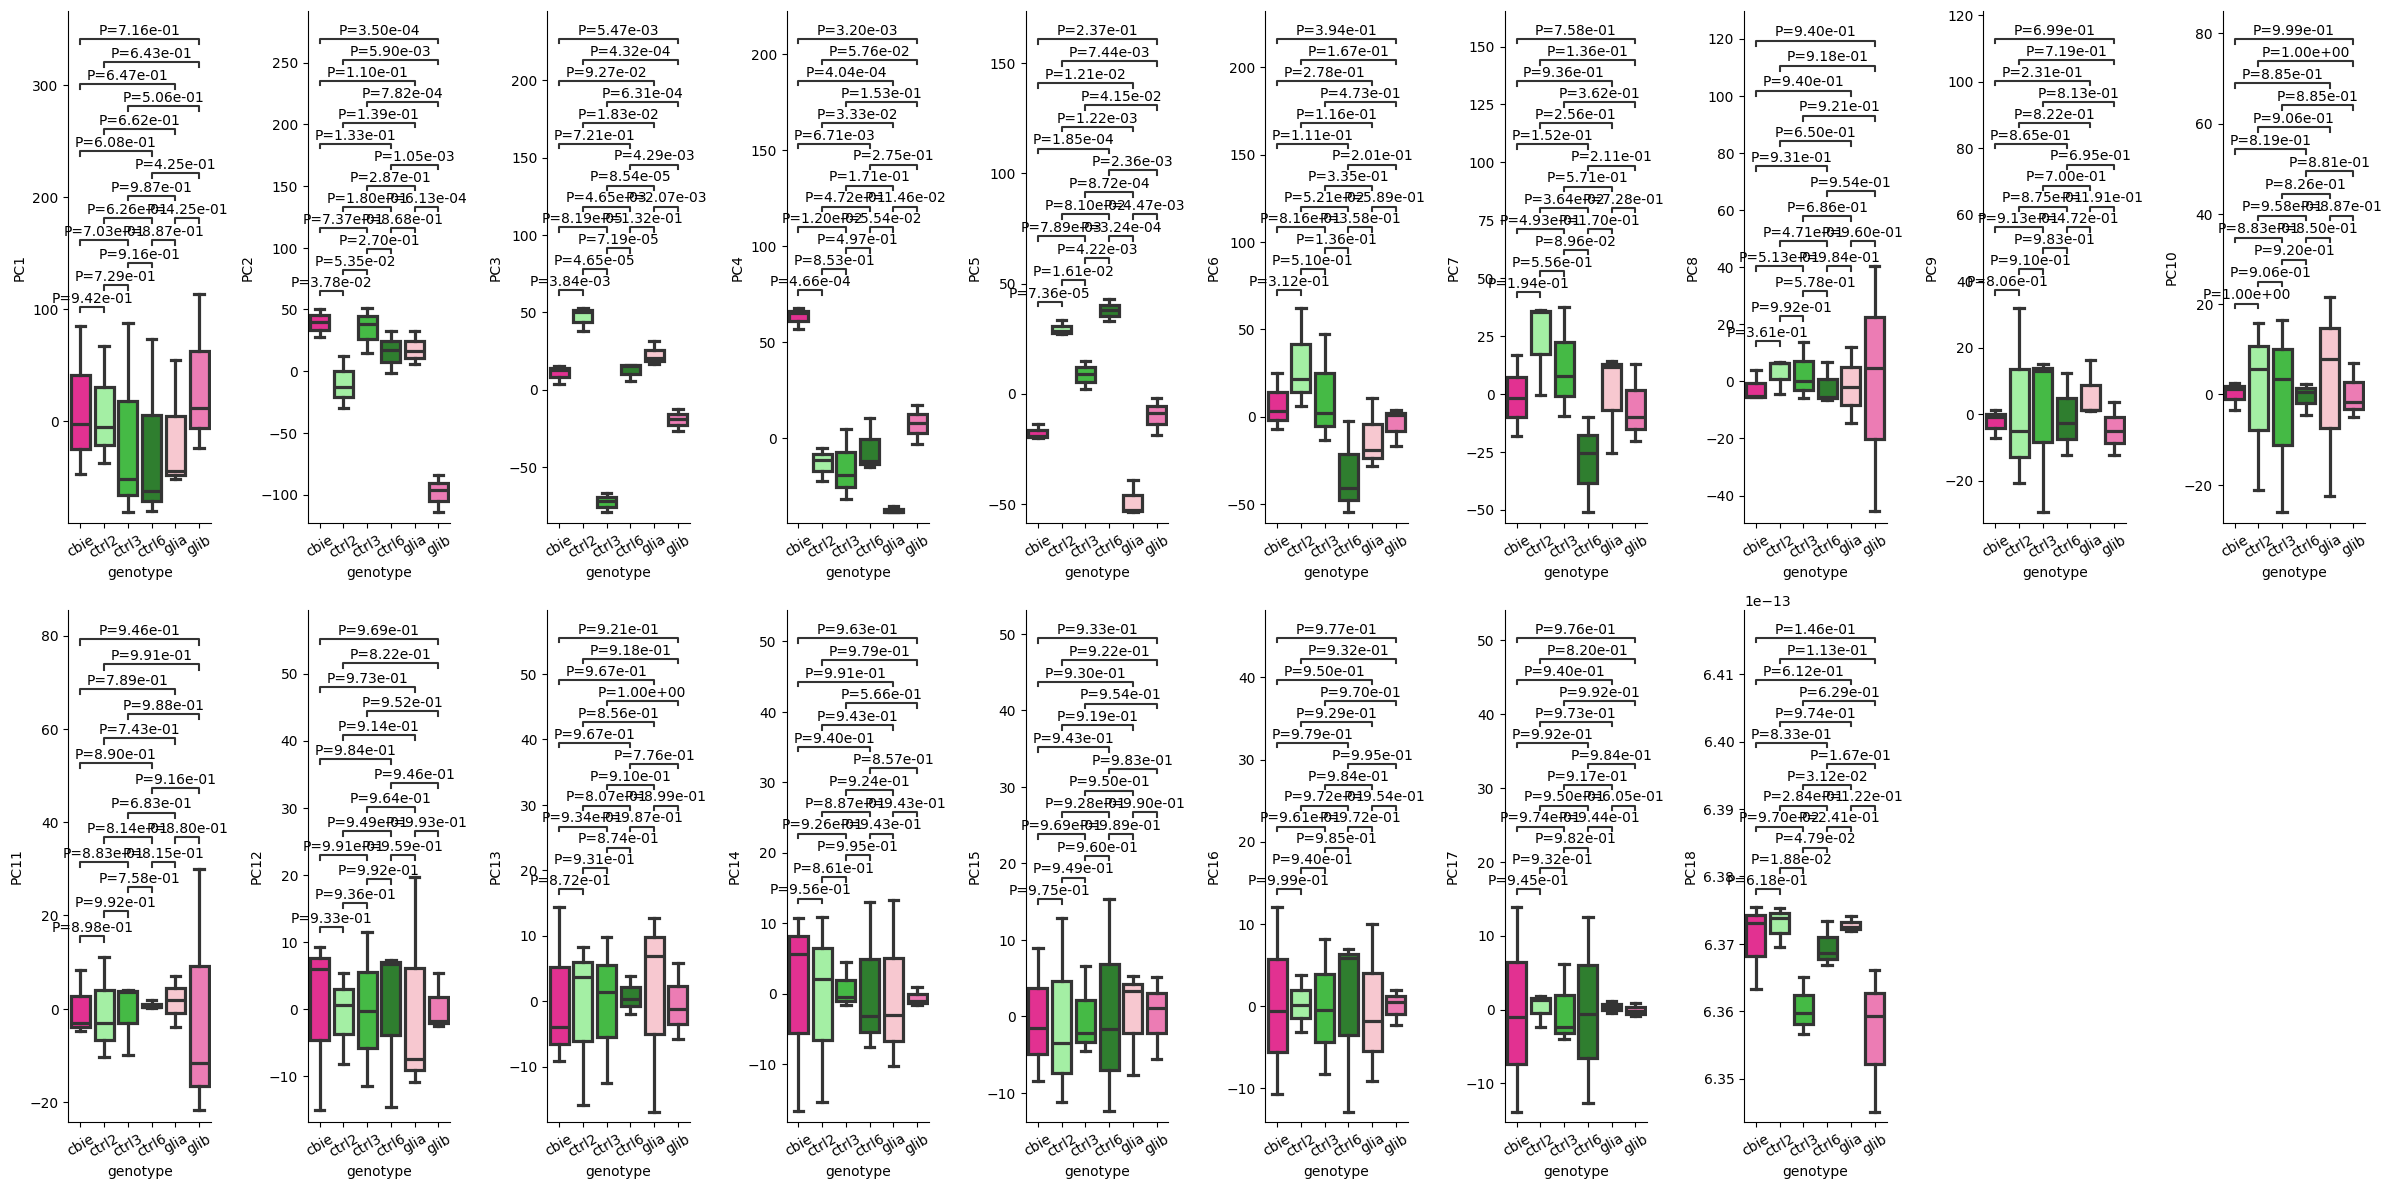

In [64]:
boxplot_pca_significance(genes_dataset.pca, treatment_col='genotype', fontsize=10, palette=palette_genotype)

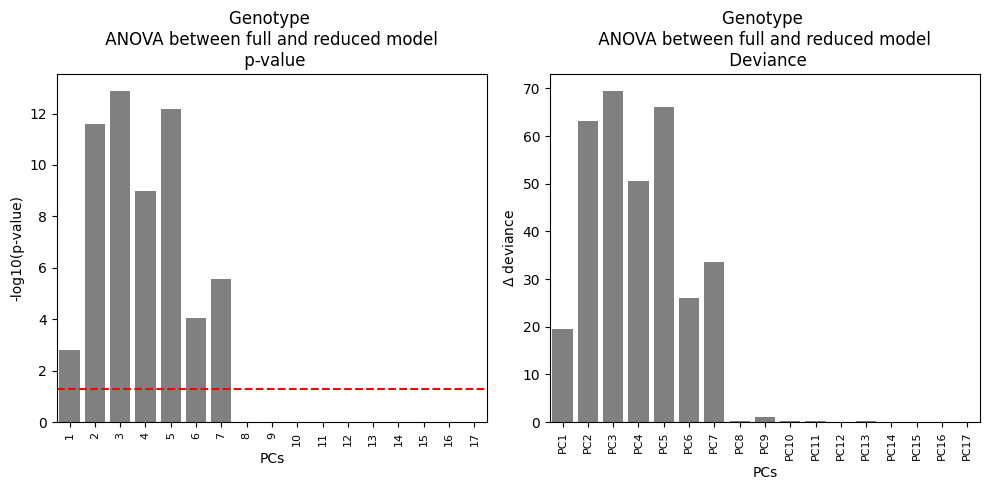

In [65]:
%%capture cap --no-display

from melapa.LMM_helper import lmer_per_PC_re

## See which component captures the difference sensitive/resistant

plt.figure(figsize=(10, 5))
## See which component captures the batch
anovas = []
p_vals = []

for i in range(17):
    PC = i+1
    anova, p_val = lmer_per_PC_re(genes_dataset.pca, random_effects=['treatment'], fixed_effect='genotype', PC=PC)
    anovas.append(anova)
    p_vals.append(p_val)

plt.subplot(1, 2, 1)
sns.barplot(x=np.arange(1, 18), y=-np.log10(p_vals), color='grey')
plt.axhline(y=-np.log10(0.05), color='red', linestyle='--')
plt.xticks(rotation=90, fontsize=8);
plt.xlabel('PCs')
plt.ylabel('-log10(p-value)')
plt.title(f'Genotype \n ANOVA between full and reduced model \n p-value')

delta_deviances = []
for PC in range(len(anovas)):
    delta_deviance = anovas[PC].loc['MODEL2', 'deviance'] - anovas[PC].loc['MODEL1', 'deviance'] ## Difference between the full and reduced model
    delta_deviances.append(delta_deviance)

plt.subplot(1, 2, 2)
sns.barplot(x=[f"PC{i+1}" for i in range(len(anovas))], y=delta_deviances, color='grey')
#plt.axhline(y=-np.log10(0.05), color='red', linestyle='--')
plt.xticks(rotation=90, fontsize=8);
plt.xlabel('PCs')
plt.ylabel(r'$\Delta$ deviance')
plt.title(f'Genotype \n ANOVA between full and reduced model \n Deviance')

plt.tight_layout()

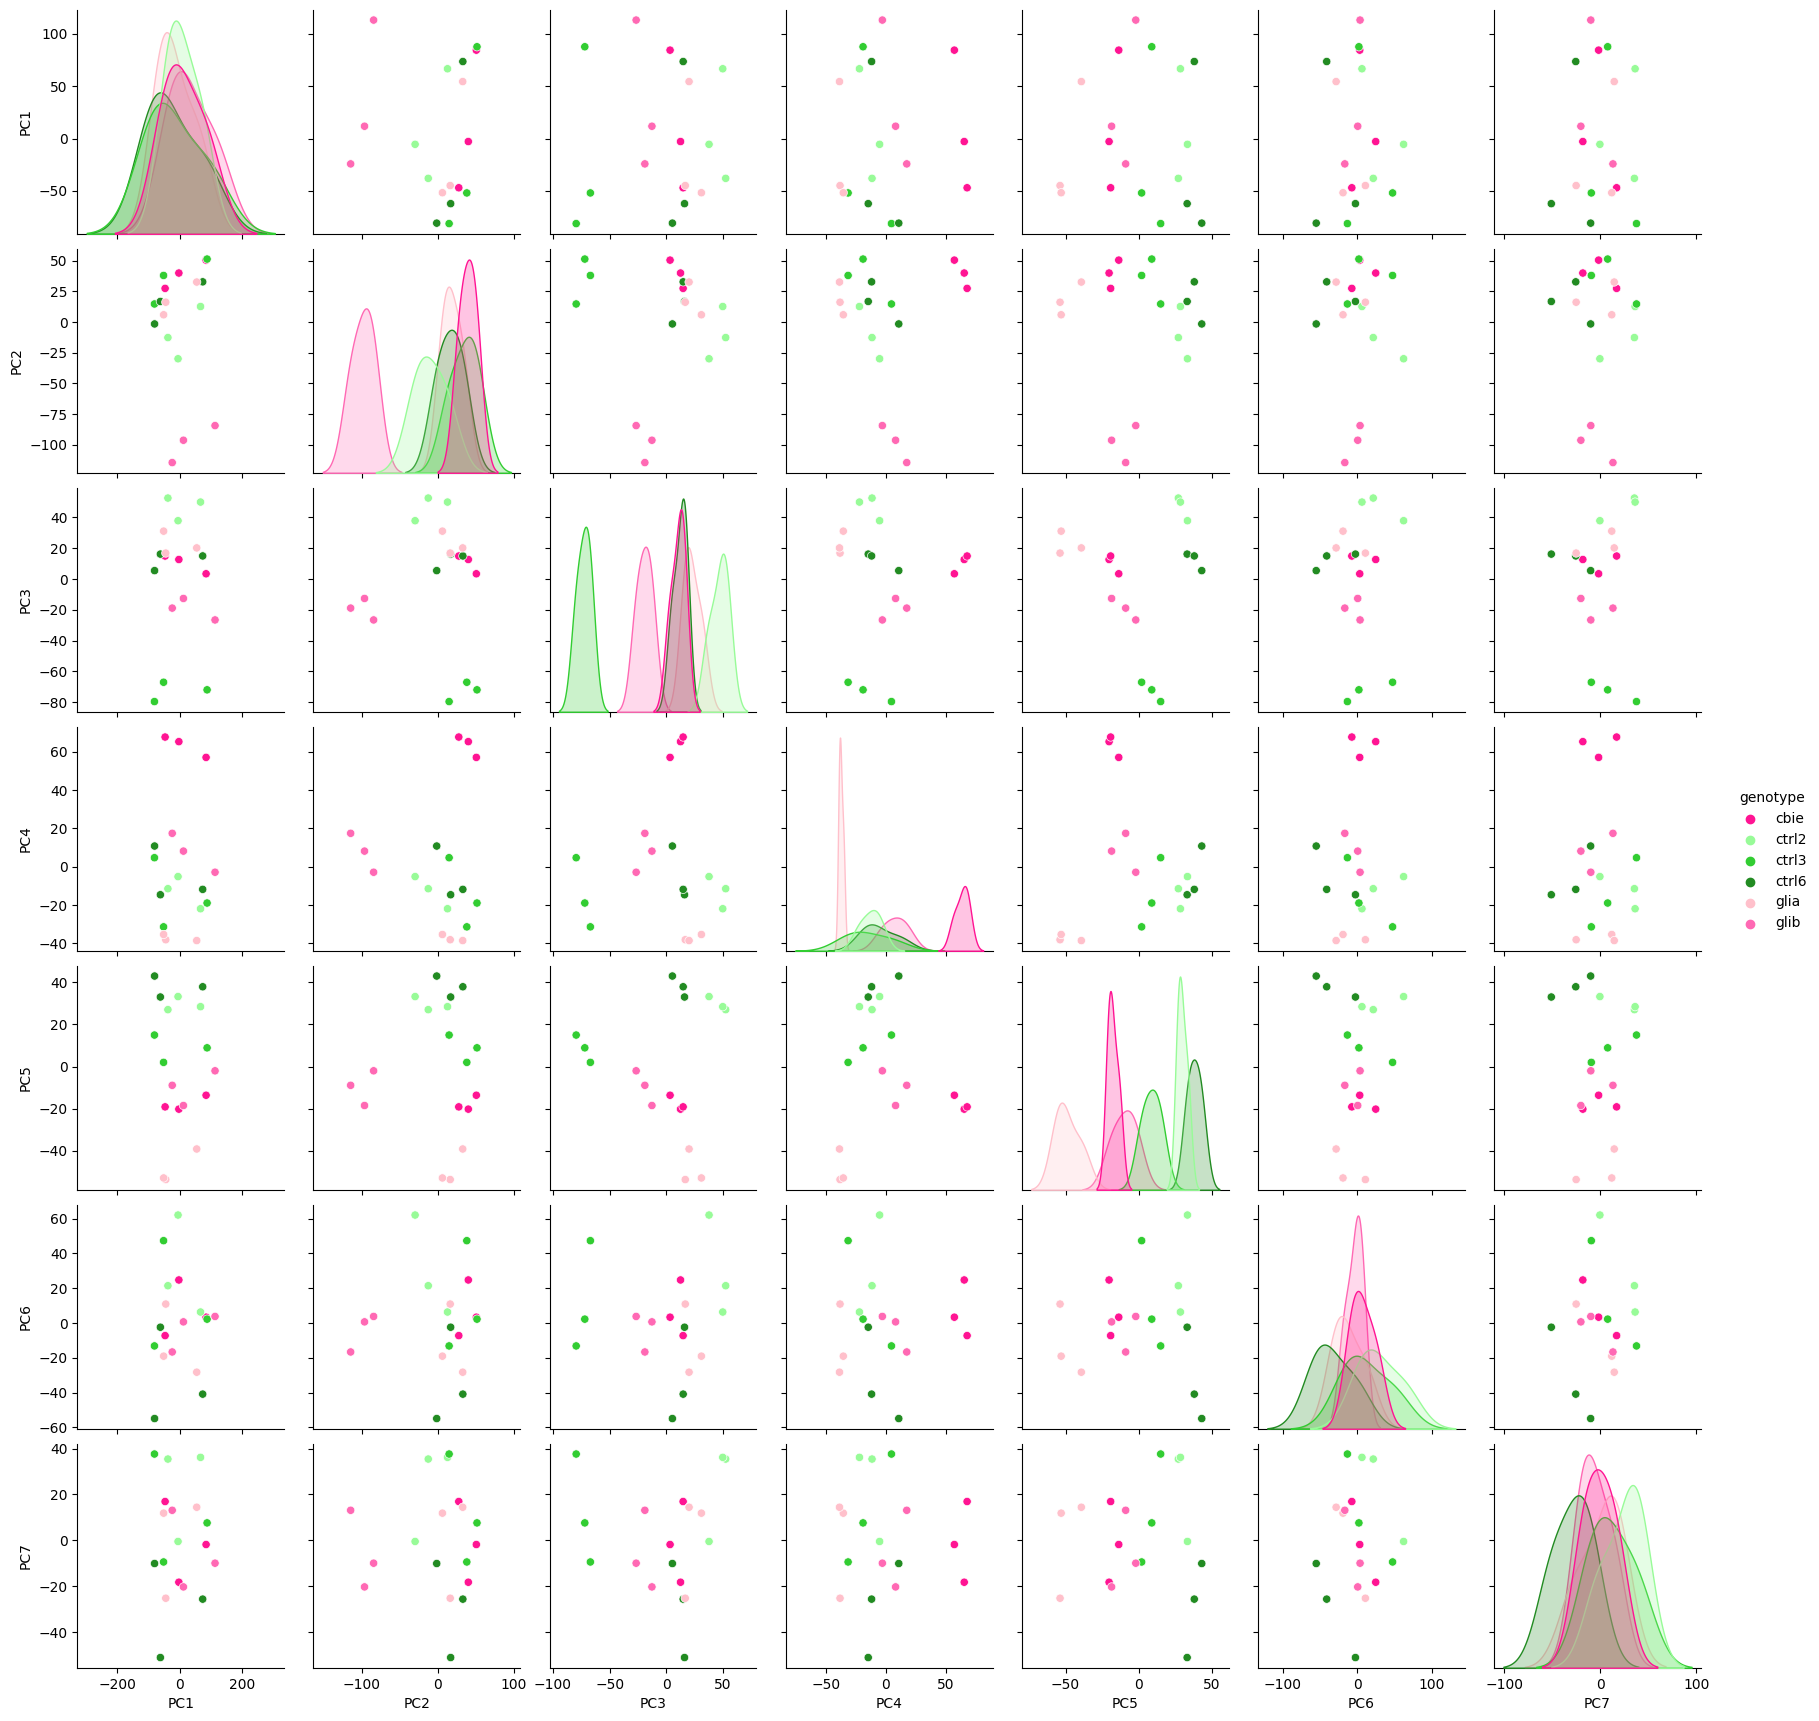

In [66]:
PCs = [f"PC{PC+1}" for PC in list(np.argwhere(np.array(p_vals) < 0.05).flatten())] + ['genotype']
sns.pairplot(genes_dataset.pca[PCs], hue='genotype',  palette=palette_genotype)

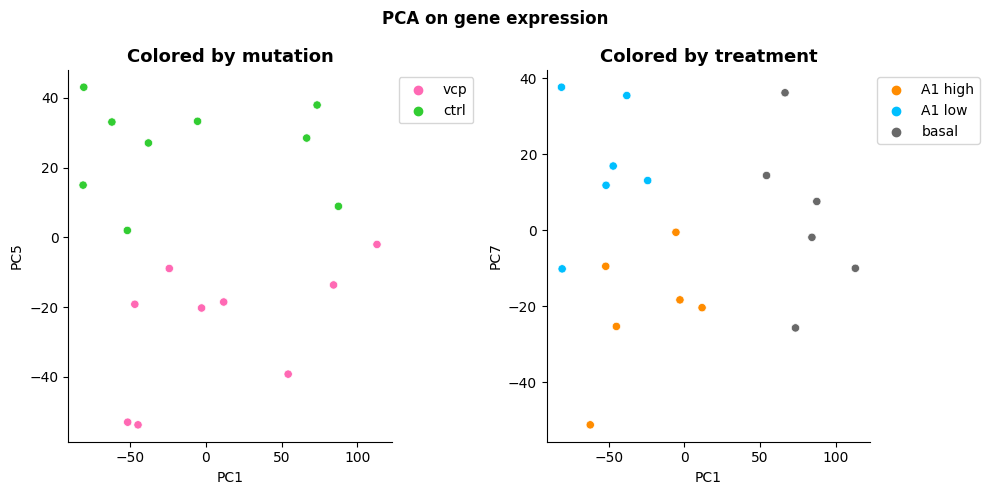

In [67]:
plt.figure(figsize=(10, 5))
plt.subplot(1,2,1)
sns.scatterplot(data=genes_dataset.pca, x='PC1', y='PC5', hue='mutation', palette={'ctrl': 'limegreen', 'vcp': 'hotpink'})
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.title("Colored by mutation", weight='bold', fontsize=13)
sns.despine()



plt.subplot(1,2,2)
sns.scatterplot(data=genes_dataset.pca, x='PC1', y='PC7', hue='treatment', palette={'basal': 'dimgray', 'A1 low': 'deepskyblue', "A1 high": "darkorange"})
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.title("Colored by treatment", weight='bold', fontsize=13)
sns.despine()


plt.suptitle("PCA on gene expression", weight='bold')
plt.tight_layout()


In summary:
- PC1 captures untreated vs treated
- PC5 captures the mutation
- PC7 captures the difference between A1 high and A1 low

## Pathway analysis

In [71]:
import stringdb
from pybpanalysis.stringdb_helper import stringdb_barplot_all_class, stringdb_dotplot_one_class, stringdb_barplot_one_class, get_BP_heatmaps



/idiap/temp/lfournier/miniconda3/envs/scRNApy-new/lib/python3.10/site-packages/requests/__init__.py:109: RequestsDependencyWarning: urllib3 (2.5.0) or chardet (None)/charset_normalizer (2.1.1) doesn't match a supported version!
  warnings.warn(


/idiap/temp/lfournier/miniconda3/envs/scRNApy-new/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(


Number of pairs specific to the treated extreme: 877
Number of pairs specific to the untreated extreme: 1057


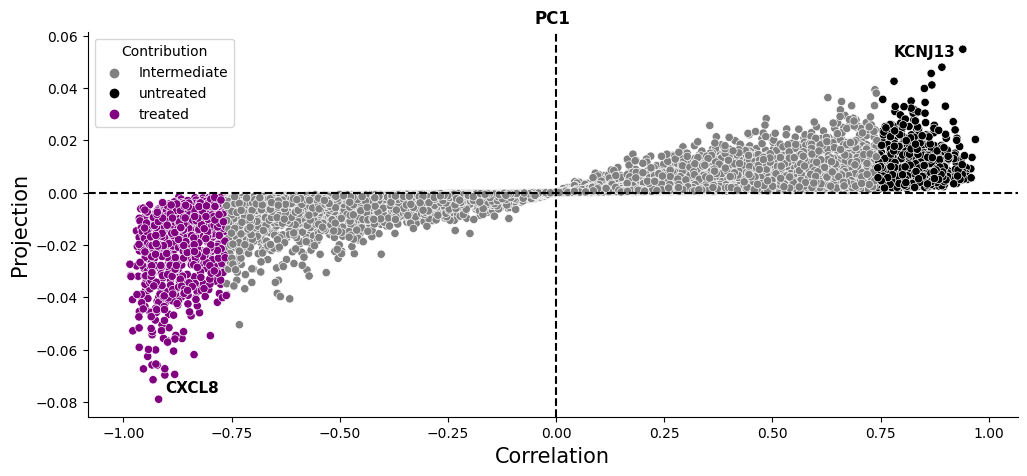

In [86]:
pairs_treated_PC1, pairs_untreated_PC1 = genes_dataset.projection_correlation_one_PC(PC=1, 
                                                                                     min_extreme='treated', 
                                                                                     max_extreme='untreated', 
                                                                                     k_clusters=12, 
                                                                                     min_extreme_color="purple", 
                                                                                     max_extreme_color="black", 
                                                                                     sort_by='projection', 
                                                                                     scaling=False)

sns.despine()
plt.title('PC1', weight='bold')
print(f"Number of pairs specific to the treated extreme: {len(pairs_treated_PC1)}")
print(f"Number of pairs specific to the untreated extreme: {len(pairs_untreated_PC1)}")

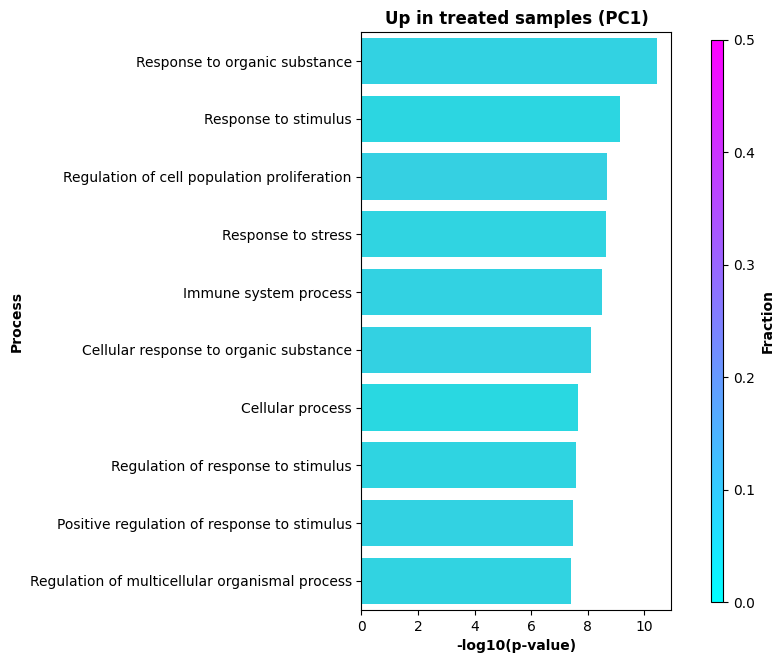

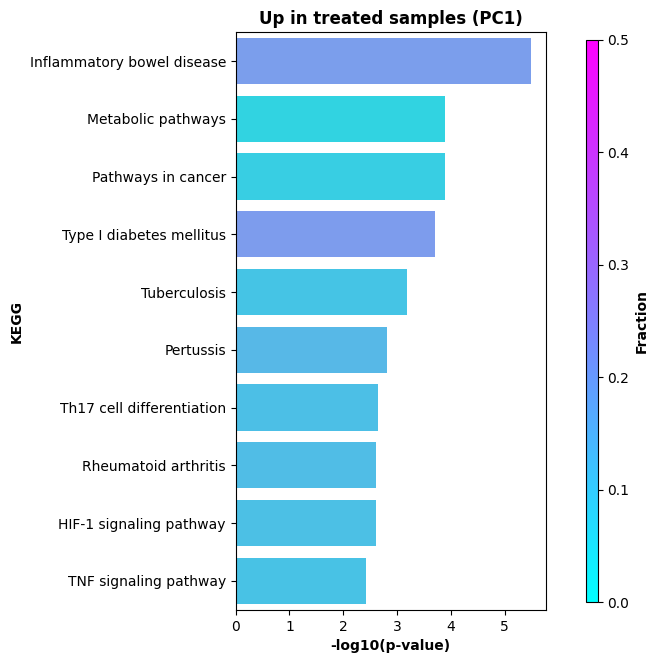

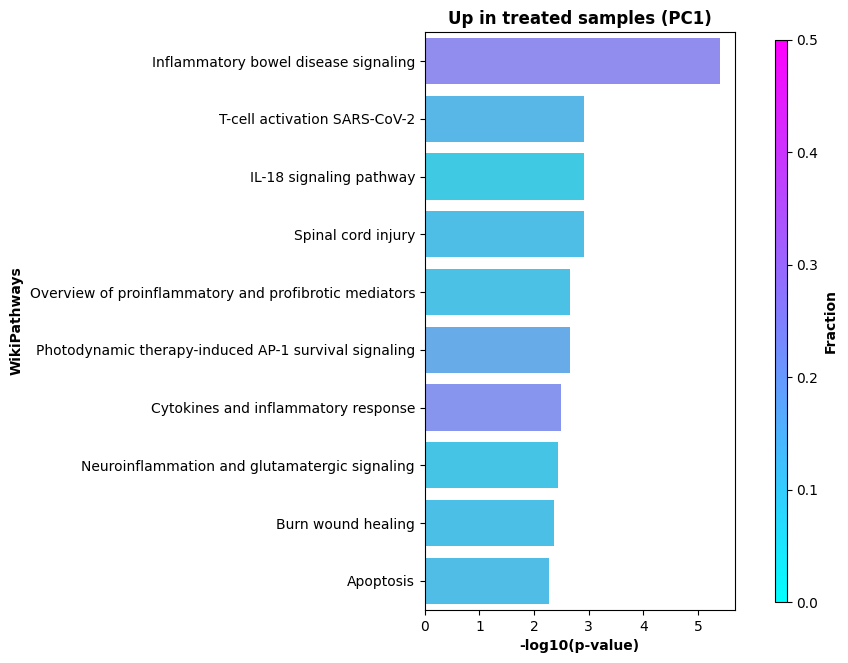

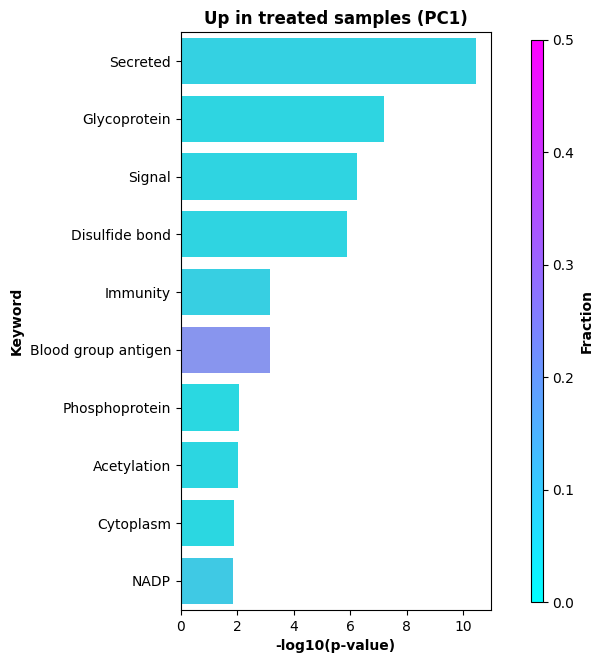

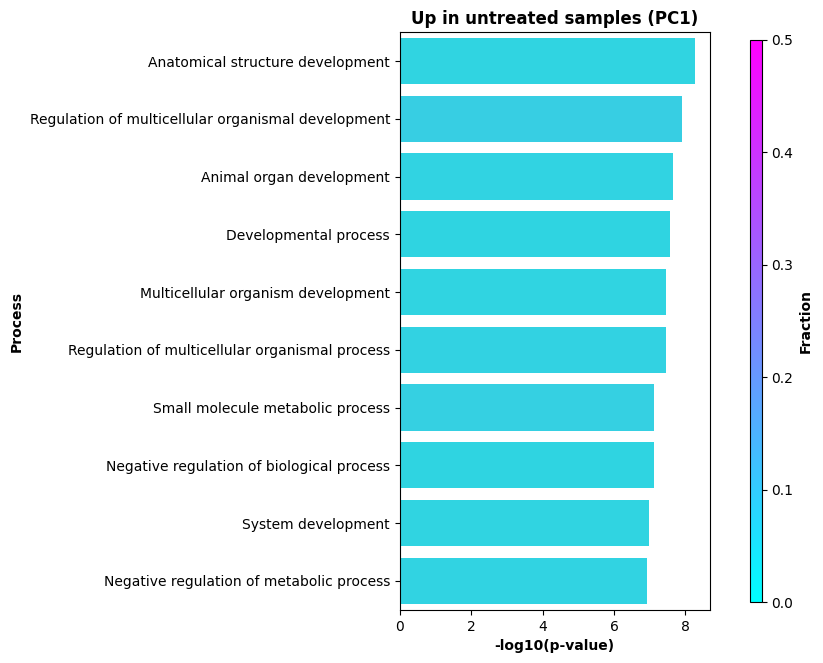

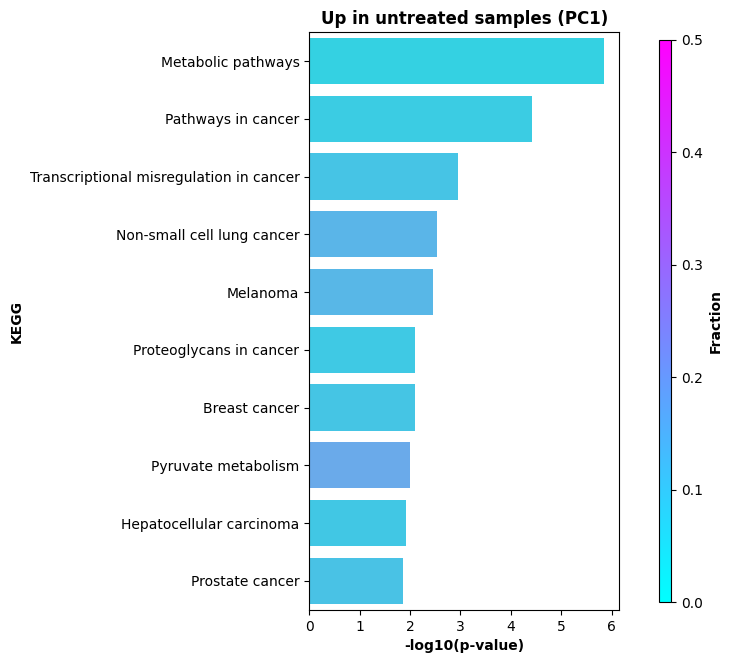

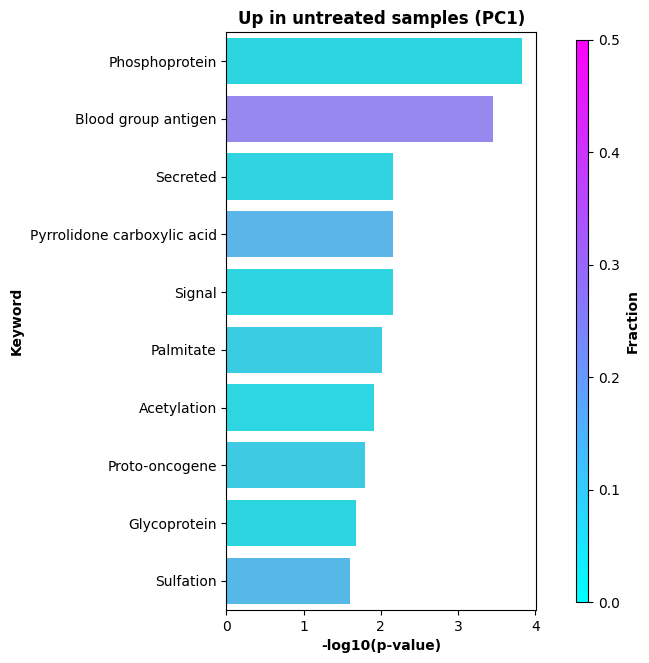

In [77]:
from matplotlib import cm
string_ids = stringdb.get_string_ids([pair.split('/')[0][:-2] for pair in pairs_treated_PC1])
enrichment_df_PUD_PC3_acquired = stringdb.get_enrichment(string_ids.queryItem)
enrichment_df_PUD_PC3_acquired = enrichment_df_PUD_PC3_acquired[enrichment_df_PUD_PC3_acquired['number_of_genes'] >= 5]
if 'Process' in enrichment_df_PUD_PC3_acquired.value_counts('category').index:
    stringdb_barplot_one_class(df=enrichment_df_PUD_PC3_acquired, nb_top=10, clas='Process', cmap=cm.cool, title='Up in treated samples (PC1)', vmin=0, vmax=0.5, frac_x=False)
if 'KEGG' in enrichment_df_PUD_PC3_acquired.value_counts('category').index:
    stringdb_barplot_one_class(df=enrichment_df_PUD_PC3_acquired, nb_top=10, clas='KEGG', cmap=cm.cool, title='Up in treated samples (PC1)', vmin=0, vmax=0.5, frac_x=False)
if 'WikiPathways' in enrichment_df_PUD_PC3_acquired.value_counts('category').index:
    stringdb_barplot_one_class(df=enrichment_df_PUD_PC3_acquired, nb_top=10, clas='WikiPathways', cmap=cm.cool, title='Up in treated samples (PC1)', vmin=0, vmax=0.5, frac_x=False)
if 'Keyword' in enrichment_df_PUD_PC3_acquired.value_counts('category').index:

    stringdb_barplot_one_class(df=enrichment_df_PUD_PC3_acquired, nb_top=10, clas='Keyword', cmap=cm.cool, title='Up in treated samples (PC1)', vmin=0, vmax=0.5, frac_x=False)

from matplotlib import cm
string_ids = stringdb.get_string_ids([pair.split('/')[0][:-2] for pair in pairs_untreated_PC1])
enrichment_df_PUD_PC3_innate = stringdb.get_enrichment(string_ids.queryItem)
enrichment_df_PUD_PC3_innate = enrichment_df_PUD_PC3_innate[enrichment_df_PUD_PC3_innate['number_of_genes'] >= 5]
if 'Process' in enrichment_df_PUD_PC3_innate.value_counts('category').index:
    stringdb_barplot_one_class(df=enrichment_df_PUD_PC3_innate, nb_top=10, clas='Process', cmap=cm.cool, title='Up in untreated samples (PC1)', vmin=0, vmax=0.5, frac_x=False)
if 'KEGG' in enrichment_df_PUD_PC3_innate.value_counts('category').index:
    stringdb_barplot_one_class(df=enrichment_df_PUD_PC3_innate, nb_top=10, clas='KEGG', cmap=cm.cool, title='Up in untreated samples (PC1)', vmin=0, vmax=0.5, frac_x=False)
if 'WikiPathways' in enrichment_df_PUD_PC3_innate.value_counts('category').index:
    stringdb_barplot_one_class(df=enrichment_df_PUD_PC3_innate, nb_top=10, clas='WikiPathways', cmap=cm.cool, title='Up in untreated samples (PC1)', vmin=0, vmax=0.5, frac_x=False)
if 'Keyword' in enrichment_df_PUD_PC3_innate.value_counts('category').index:
    stringdb_barplot_one_class(df=enrichment_df_PUD_PC3_innate, nb_top=10, clas='Keyword', cmap=cm.cool, title='Up in untreated samples (PC1)', vmin=0, vmax=0.5, frac_x=False)

/idiap/temp/lfournier/miniconda3/envs/scRNApy-new/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(


Number of pairs specific to the VCP extreme: 454
Number of pairs specific to the CTRL extreme: 290


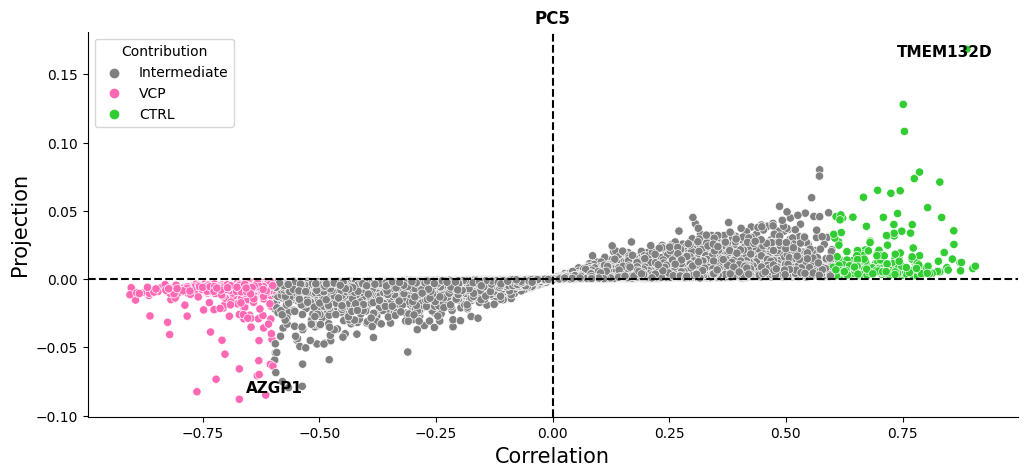

In [70]:
pairs_vcp_PC5, pairs_ctrl_PC5 = genes_dataset.projection_correlation_one_PC(PC=5, 
                                                                                     min_extreme='VCP', 
                                                                                     max_extreme='CTRL', 
                                                                                     k_clusters=12, 
                                                                                     min_extreme_color="hotpink", 
                                                                                     max_extreme_color="limegreen", 
                                                                                     sort_by='projection', 
                                                                                     scaling=False)

sns.despine()
plt.title('PC5', weight='bold')
print(f"Number of pairs specific to the VCP extreme: {len(pairs_vcp_PC5)}")
print(f"Number of pairs specific to the CTRL extreme: {len(pairs_ctrl_PC5)}")


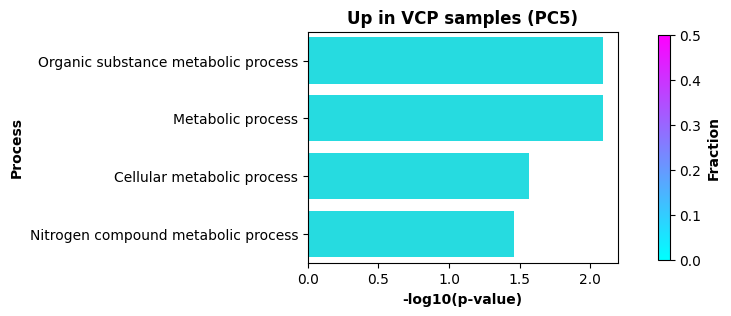

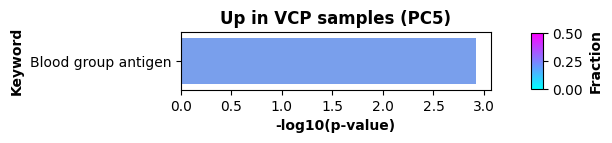

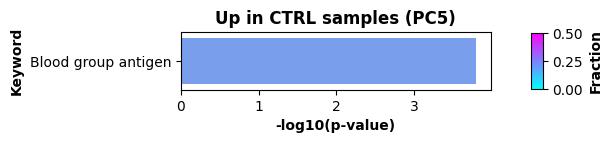

In [73]:
from matplotlib import cm
string_ids = stringdb.get_string_ids([pair.split('/')[0][:-2] for pair in pairs_vcp_PC5])
enrichment_df_PUD_PC3_acquired = stringdb.get_enrichment(string_ids.queryItem)
enrichment_df_PUD_PC3_acquired = enrichment_df_PUD_PC3_acquired[enrichment_df_PUD_PC3_acquired['number_of_genes'] >= 5]
if 'Process' in enrichment_df_PUD_PC3_acquired.value_counts('category').index:
    stringdb_barplot_one_class(df=enrichment_df_PUD_PC3_acquired, nb_top=10, clas='Process', cmap=cm.cool, title='Up in VCP samples (PC5)', vmin=0, vmax=0.5, frac_x=False)
if 'KEGG' in enrichment_df_PUD_PC3_acquired.value_counts('category').index:
    stringdb_barplot_one_class(df=enrichment_df_PUD_PC3_acquired, nb_top=10, clas='KEGG', cmap=cm.cool, title='Up in VCP samples (PC5)', vmin=0, vmax=0.5, frac_x=False)
if 'WikiPathways' in enrichment_df_PUD_PC3_acquired.value_counts('category').index:
    stringdb_barplot_one_class(df=enrichment_df_PUD_PC3_acquired, nb_top=10, clas='WikiPathways', cmap=cm.cool, title='Up in VCP samples (PC5)', vmin=0, vmax=0.5, frac_x=False)
if 'Keyword' in enrichment_df_PUD_PC3_acquired.value_counts('category').index:

    stringdb_barplot_one_class(df=enrichment_df_PUD_PC3_acquired, nb_top=10, clas='Keyword', cmap=cm.cool, title='Up in VCP samples (PC5)', vmin=0, vmax=0.5, frac_x=False)

from matplotlib import cm
string_ids = stringdb.get_string_ids([pair.split('/')[0][:-2] for pair in pairs_ctrl_PC5])
enrichment_df_PUD_PC3_innate = stringdb.get_enrichment(string_ids.queryItem)
enrichment_df_PUD_PC3_innate = enrichment_df_PUD_PC3_innate[enrichment_df_PUD_PC3_innate['number_of_genes'] >= 5]
if 'Process' in enrichment_df_PUD_PC3_innate.value_counts('category').index:
    stringdb_barplot_one_class(df=enrichment_df_PUD_PC3_innate, nb_top=10, clas='Process', cmap=cm.cool, title='Up in CTRL samples (PC5)', vmin=0, vmax=0.5, frac_x=False)
if 'KEGG' in enrichment_df_PUD_PC3_innate.value_counts('category').index:
    stringdb_barplot_one_class(df=enrichment_df_PUD_PC3_innate, nb_top=10, clas='KEGG', cmap=cm.cool, title='Up in CTRL samples (PC5)', vmin=0, vmax=0.5, frac_x=False)
if 'WikiPathways' in enrichment_df_PUD_PC3_innate.value_counts('category').index:
    stringdb_barplot_one_class(df=enrichment_df_PUD_PC3_innate, nb_top=10, clas='WikiPathways', cmap=cm.cool, title='Up in CTRL samples (PC5)', vmin=0, vmax=0.5, frac_x=False)
if 'Keyword' in enrichment_df_PUD_PC3_innate.value_counts('category').index:
    stringdb_barplot_one_class(df=enrichment_df_PUD_PC3_innate, nb_top=10, clas='Keyword', cmap=cm.cool, title='Up in CTRL samples (PC5)', vmin=0, vmax=0.5, frac_x=False)

/idiap/temp/lfournier/miniconda3/envs/scRNApy-new/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(


Number of pairs specific to the A1 high extreme: 181
Number of pairs specific to the A1 low extreme: 256


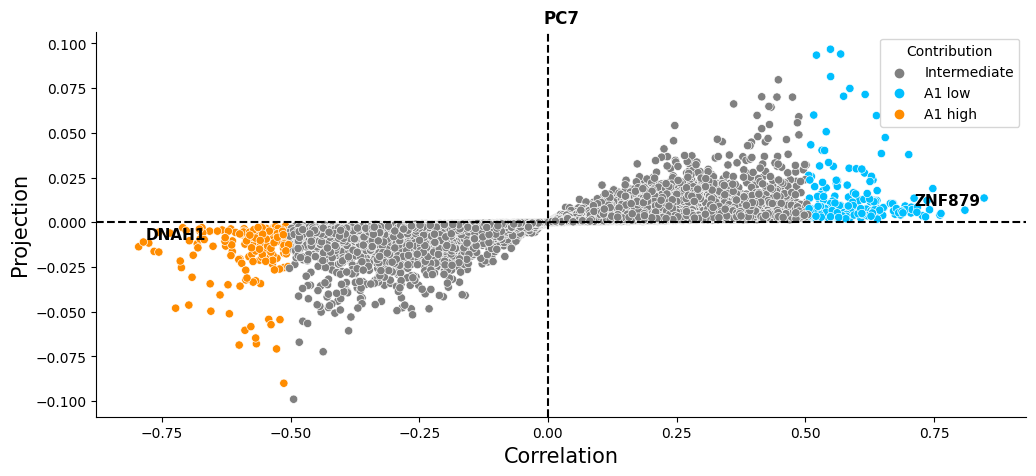

In [79]:
pairs_a1_high_PC7, pairs_a1_low_PC7 = genes_dataset.projection_correlation_one_PC(PC=7, 
                                                                                     min_extreme='A1 high', 
                                                                                     max_extreme='A1 low', 
                                                                                     k_clusters=12, 
                                                                                     min_extreme_color="darkorange", 
                                                                                     max_extreme_color="deepskyblue", 
                                                                                     sort_by='correlation', 
                                                                                     scaling=False)

sns.despine()
plt.title('PC7', weight='bold')
print(f"Number of pairs specific to the A1 high extreme: {len(pairs_a1_high_PC7)}")
print(f"Number of pairs specific to the A1 low extreme: {len(pairs_a1_low_PC7)}")

In [80]:
from matplotlib import cm
string_ids = stringdb.get_string_ids([pair.split('/')[0][:-2] for pair in pairs_a1_low_PC7])
enrichment_df_PUD_PC3_acquired = stringdb.get_enrichment(string_ids.queryItem)
enrichment_df_PUD_PC3_acquired = enrichment_df_PUD_PC3_acquired[enrichment_df_PUD_PC3_acquired['number_of_genes'] >= 5]
if 'Process' in enrichment_df_PUD_PC3_acquired.value_counts('category').index:
    stringdb_barplot_one_class(df=enrichment_df_PUD_PC3_acquired, nb_top=10, clas='Process', cmap=cm.cool, title='Up in A1 low samples (PC7)', vmin=0, vmax=0.5, frac_x=False)
if 'KEGG' in enrichment_df_PUD_PC3_acquired.value_counts('category').index:
    stringdb_barplot_one_class(df=enrichment_df_PUD_PC3_acquired, nb_top=10, clas='KEGG', cmap=cm.cool, title='Up in A1 low samples (PC7)', vmin=0, vmax=0.5, frac_x=False)
if 'WikiPathways' in enrichment_df_PUD_PC3_acquired.value_counts('category').index:
    stringdb_barplot_one_class(df=enrichment_df_PUD_PC3_acquired, nb_top=10, clas='WikiPathways', cmap=cm.cool, title='Up in A1 low samples (PC7)', vmin=0, vmax=0.5, frac_x=False)
if 'Keyword' in enrichment_df_PUD_PC3_acquired.value_counts('category').index:

    stringdb_barplot_one_class(df=enrichment_df_PUD_PC3_acquired, nb_top=10, clas='Keyword', cmap=cm.cool, title='Up in A1 low samples (PC7)', vmin=0, vmax=0.5, frac_x=False)

from matplotlib import cm
string_ids = stringdb.get_string_ids([pair.split('/')[0][:-2] for pair in pairs_a1_high_PC7])
enrichment_df_PUD_PC3_innate = stringdb.get_enrichment(string_ids.queryItem)
enrichment_df_PUD_PC3_innate = enrichment_df_PUD_PC3_innate[enrichment_df_PUD_PC3_innate['number_of_genes'] >= 5]
if 'Process' in enrichment_df_PUD_PC3_innate.value_counts('category').index:
    stringdb_barplot_one_class(df=enrichment_df_PUD_PC3_innate, nb_top=10, clas='Process', cmap=cm.cool, title='Up in A1 high samples (PC7)', vmin=0, vmax=0.5, frac_x=False)
if 'KEGG' in enrichment_df_PUD_PC3_innate.value_counts('category').index:
    stringdb_barplot_one_class(df=enrichment_df_PUD_PC3_innate, nb_top=10, clas='KEGG', cmap=cm.cool, title='Up in A1 high samples (PC7)', vmin=0, vmax=0.5, frac_x=False)
if 'WikiPathways' in enrichment_df_PUD_PC3_innate.value_counts('category').index:
    stringdb_barplot_one_class(df=enrichment_df_PUD_PC3_innate, nb_top=10, clas='WikiPathways', cmap=cm.cool, title='Up in A1 high samples (PC7)', vmin=0, vmax=0.5, frac_x=False)
if 'Keyword' in enrichment_df_PUD_PC3_innate.value_counts('category').index:
    stringdb_barplot_one_class(df=enrichment_df_PUD_PC3_innate, nb_top=10, clas='Keyword', cmap=cm.cool, title='Up in A1 high samples (PC7)', vmin=0, vmax=0.5, frac_x=False)